<a href="https://colab.research.google.com/github/annabellemeyer2-prog/ML441-Assignment3/blob/main/27129160RW441assignment3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Datasets

Six datasets are used for this assignment, three classification and three
function approximation, all sourced from the UCI Machine Learning
Repository. Datasets were filtered to an instance-count range of 100 to
1000, following the same reasoning used by Tschernutter et al. (2024) in
selecting UCI regression benchmarks: fewer than 100 instances risks not
providing enough data to meaningfully train and test a neural network,
while more than 1000 becomes computationally demanding across repeated
train-test splits.

### Classification

| Dataset | Instances | Features | Classes |
|---|---|---|---|
| Wine | 178 | 13 | 3 (balanced) |
| Ionosphere | 351 | 33 | 2 |
| Breast Cancer Wisconsin (Diagnostic) | 569 | 30 | 2 (imbalanced) |

### Function approximation (regression)

| Dataset | Instances | Features |
|---|---|---|
| Yacht Hydrodynamics | 308 | 6 |
| Auto MPG | 398 | 7 |
| Energy Efficiency | 768 | 8 |

Datasets were chosen to vary across the dimensions established in the data
complexity literature (Ho and Basu, 2002): dimensionality (feature count),
sample size, and, for classification, class count and class balance. Auto
MPG additionally contains missing values, the only dataset in the set of
six to do so.

In [1]:
!pip install -q ucimlrepo

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from ucimlrepo import fetch_ucirepo
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import LeaveOneOut

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.model_selection import cross_val_score

from sklearn.model_selection import train_test_split

from sklearn.model_selection import RepeatedStratifiedKFold, RepeatedKFold
from sklearn.metrics import accuracy_score, f1_score, mean_squared_error, r2_score

pd.set_option("display.max_columns", None)

In [2]:
from sklearn.datasets import fetch_openml

datasets = {}
load_errors = {}

def safe_load(key, loader_fn):
    try:
        datasets[key] = loader_fn()
        print(f"{key}: loaded OK")
    except Exception as e:
        load_errors[key] = str(e)
        print(f"{key}: FAILED — {e}")

# Classification
safe_load("wine", lambda: fetch_ucirepo(id=109))
safe_load("ionosphere", lambda: fetch_ucirepo(name="Ionosphere"))
safe_load("breast_cancer", lambda: fetch_ucirepo(id=17))

# Regression
safe_load("yacht", lambda: fetch_openml(data_id=42370, as_frame=True))
safe_load("auto_mpg", lambda: fetch_ucirepo(id=9))
safe_load("energy", lambda: fetch_ucirepo(id=242))

print()
print("Loaded:", list(datasets.keys()))
print("Failed:", list(load_errors.keys()))

wine: loaded OK
ionosphere: loaded OK
breast_cancer: loaded OK
yacht: loaded OK
auto_mpg: loaded OK
energy: loaded OK

Loaded: ['wine', 'ionosphere', 'breast_cancer', 'yacht', 'auto_mpg', 'energy']
Failed: []


In [3]:
if "yacht" in datasets:
    yacht_raw = datasets["yacht"]
    yacht_X = yacht_raw.data
    yacht_y = yacht_raw.target.to_frame(name="residuary_resistance")

    class _DataWrapper:
        pass
    wrapped = _DataWrapper()
    wrapped.features = yacht_X
    wrapped.targets = yacht_y

    class _DatasetWrapper:
        pass
    yacht_wrapped = _DatasetWrapper()
    yacht_wrapped.data = wrapped
    yacht_wrapped.metadata = type("meta", (), {"name": "Yacht Hydrodynamics"})()

    datasets["yacht"] = yacht_wrapped

    print("Yacht reshaped:", datasets["yacht"].data.features.shape, datasets["yacht"].data.targets.shape)

Yacht reshaped: (308, 6) (308, 1)


## Data understanding checks

Before any preprocessing decisions are made, each dataset is checked for
the following, per course convention and the complexity dimensions
discussed earlier:

- **Structure**: instance count, feature count, and missing values per
  column, computed directly from the loaded data rather than taken from
  documentation.
- **Class balance** (classification datasets only): the distribution of
  target classes, to identify any imbalance.
- **Skewness**: assessed from histogram shape using course vocabulary
  (Uniform, Normal, Skewed left, Skewed right, Exponential, Multimodal),
  not from a computed skewness statistic such as `scipy.stats.skew()`.
- **Outliers**: assessed using the gap-comparison method as taught, which
  compares the gaps between the five-number summary values (minimum, 1st
  quartile, median, 3rd quartile, maximum) rather than Tukey fences. A
  gap between the maximum and 3rd quartile that is much larger than the
  gap between the 3rd quartile and median suggests the maximum is an
  outlier, and likewise for the minimum against the 1st quartile and
  median. No fixed numeric threshold is applied automatically; ratios are
  used to rank candidate features, and outlier status is confirmed
  visually from the corresponding histogram.
- **Separability** (classification datasets only): a leave-one-out 1-NN
  error rate and Fisher's discriminant ratio are computed per dataset, as
  established complexity measures from Ho and Basu (2002), to give an
  evidence-based sense of how separable each classification problem
  actually is, rather than relying on general reputation.

In [4]:
def summarise(name, ds):
    X = ds.data.features
    y = ds.data.targets
    print(f"--- {name} ---")
    print("Instances:", X.shape[0])
    print("Features:", X.shape[1])
    missing = X.isnull().sum()
    print("Missing values per column:")
    print(missing[missing > 0] if missing.sum() > 0 else "None")
    print()

def class_balance(name, ds):
    y = ds.data.targets.iloc[:, 0]
    print(f"--- {name} class distribution ---")
    print(y.value_counts())
    print((y.value_counts(normalize=True) * 100).round(1))
    print()

def plot_histograms(name, X, ncols=4):
    numeric_cols = X.select_dtypes(include=np.number).columns
    nrows = int(np.ceil(len(numeric_cols) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4*ncols, 3*nrows))
    axes = axes.flatten()
    for i, col in enumerate(numeric_cols):
        axes[i].hist(X[col].dropna(), bins=20, edgecolor="black")
        axes[i].set_title(col, fontsize=9)
    for j in range(i+1, len(axes)):
        axes[j].axis("off")
    fig.suptitle(name)
    plt.tight_layout()
    plt.show()

def gap_comparison_outliers(name, X):
    numeric = X.select_dtypes(include=np.number)
    rows = []
    for col in numeric.columns:
        vals = numeric[col].dropna()
        q1, median, q3 = vals.quantile(0.25), vals.median(), vals.quantile(0.75)
        vmin, vmax = vals.min(), vals.max()

        upper_gap = vmax - q3
        upper_ref_gap = q3 - median
        lower_gap = q1 - vmin
        lower_ref_gap = median - q1

        rows.append({
            "Feature": col,
            "Max gap ratio": round(upper_gap / upper_ref_gap, 2) if upper_ref_gap > 0 else np.nan,
            "Min gap ratio": round(lower_gap / lower_ref_gap, 2) if lower_ref_gap > 0 else np.nan,
        })
    result = pd.DataFrame(rows)
    print(f"--- {name}: gap-comparison ratios (no threshold applied — for ranking only) ---")
    display(result.sort_values(by=["Max gap ratio", "Min gap ratio"], ascending=False, na_position="last"))
    return result

def one_nn_loo_error(X, y):
    X_arr = StandardScaler().fit_transform(X.select_dtypes(include=np.number).dropna())
    y_arr = y.iloc[:, 0].values
    loo = LeaveOneOut()
    errors = 0
    for train_idx, test_idx in loo.split(X_arr):
        knn = KNeighborsClassifier(n_neighbors=1)
        knn.fit(X_arr[train_idx], y_arr[train_idx])
        pred = knn.predict(X_arr[test_idx])
        if pred[0] != y_arr[test_idx][0]:
            errors += 1
    return errors / len(y_arr)

def plot_top_ratio_histograms(name, X, dq_outliers_df, top_n=6):
    df = dq_outliers_df.copy()
    df["worst_ratio"] = df[["Max gap ratio", "Min gap ratio"]].max(axis=1, skipna=True)
    top = df.dropna(subset=["worst_ratio"]).sort_values("worst_ratio", ascending=False).head(top_n)

    ncols = min(3, len(top))
    nrows = int(np.ceil(len(top) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4*ncols, 3*nrows))
    axes = np.array(axes).flatten()

    for i, row in enumerate(top.itertuples()):
        vals = X[row.Feature].dropna()
        axes[i].hist(vals, bins=20, edgecolor="black")
        axes[i].set_title(f"{row.Feature}\nratio: {row.worst_ratio:.2f}", fontsize=9)
    for j in range(i+1, len(axes)):
        axes[j].axis("off")
    fig.suptitle(f"{name} — highest gap-ratio features, for visual outlier judgement")
    plt.tight_layout()
    plt.show()

def linearity_check(X, y, cv=5):
    X_num = X.select_dtypes(include=np.number).dropna()
    y_arr = y.loc[X_num.index].iloc[:, 0].values
    X_scaled = StandardScaler().fit_transform(X_num)

    lin_scores = cross_val_score(LinearRegression(), X_scaled, y_arr, cv=cv, scoring="r2")
    knn_scores = cross_val_score(KNeighborsRegressor(n_neighbors=5), X_scaled, y_arr, cv=cv, scoring="r2")

    return lin_scores.mean(), knn_scores.mean()

def fisher_discriminant_ratio(X, y):
    X_num = X.select_dtypes(include=np.number)
    y_arr = y.iloc[:, 0].values
    classes = np.unique(y_arr)
    ratios = []
    for col in X_num.columns:
        vals = X_num[col].values
        class_means = [vals[y_arr == c].mean() for c in classes]
        class_vars = [vals[y_arr == c].var() for c in classes]
        numerator = np.var(class_means)
        denominator = np.mean(class_vars)
        ratios.append(numerator / denominator if denominator > 0 else 0)
    return max(ratios)

def plot_target_histograms(name, y, ncols=2):
    if hasattr(y, "columns"):
        cols = y.select_dtypes(include=np.number).columns
    else:
        cols = []

    if len(cols) == 0:
        # categorical target (classification) — bar plot per course convention,
        # not a histogram, since target is categorical not continuous
        series = y.iloc[:, 0] if hasattr(y, "iloc") else y
        counts = series.value_counts()
        fig, ax = plt.subplots(figsize=(4, 3))
        ax.bar(counts.index.astype(str), counts.values, edgecolor="black")
        ax.set_title(f"{name} — target (categorical)")
        plt.tight_layout()
        plt.show()
        return

    ncols_actual = min(ncols, len(cols))
    nrows = int(np.ceil(len(cols) / ncols_actual))
    fig, axes = plt.subplots(nrows, ncols_actual, figsize=(4*ncols_actual, 3*nrows))
    axes = np.atleast_1d(axes).flatten()

    for i, col in enumerate(cols):
        axes[i].hist(y[col].dropna(), bins=20, edgecolor="black")
        axes[i].set_title(f"{col} (target)", fontsize=9)
    for j in range(i+1, len(axes)):
        axes[j].axis("off")
    fig.suptitle(f"{name} — target distribution")
    plt.tight_layout()
    plt.show()

In [5]:
for key, ds in datasets.items():
    summarise(key, ds)

--- wine ---
Instances: 178
Features: 13
Missing values per column:
None

--- ionosphere ---
Instances: 351
Features: 34
Missing values per column:
None

--- breast_cancer ---
Instances: 569
Features: 30
Missing values per column:
None

--- yacht ---
Instances: 308
Features: 6
Missing values per column:
None

--- auto_mpg ---
Instances: 398
Features: 7
Missing values per column:
horsepower    6
dtype: int64

--- energy ---
Instances: 768
Features: 8
Missing values per column:
None



In [6]:
classification_keys = ["wine", "ionosphere", "breast_cancer"]

for key in classification_keys:
    class_balance(key, datasets[key])

--- wine class distribution ---
class
2    71
1    59
3    48
Name: count, dtype: int64
class
2    39.9
1    33.1
3    27.0
Name: proportion, dtype: float64

--- ionosphere class distribution ---
Class
g    225
b    126
Name: count, dtype: int64
Class
g    64.1
b    35.9
Name: proportion, dtype: float64

--- breast_cancer class distribution ---
Diagnosis
B    357
M    212
Name: count, dtype: int64
Diagnosis
B    62.7
M    37.3
Name: proportion, dtype: float64



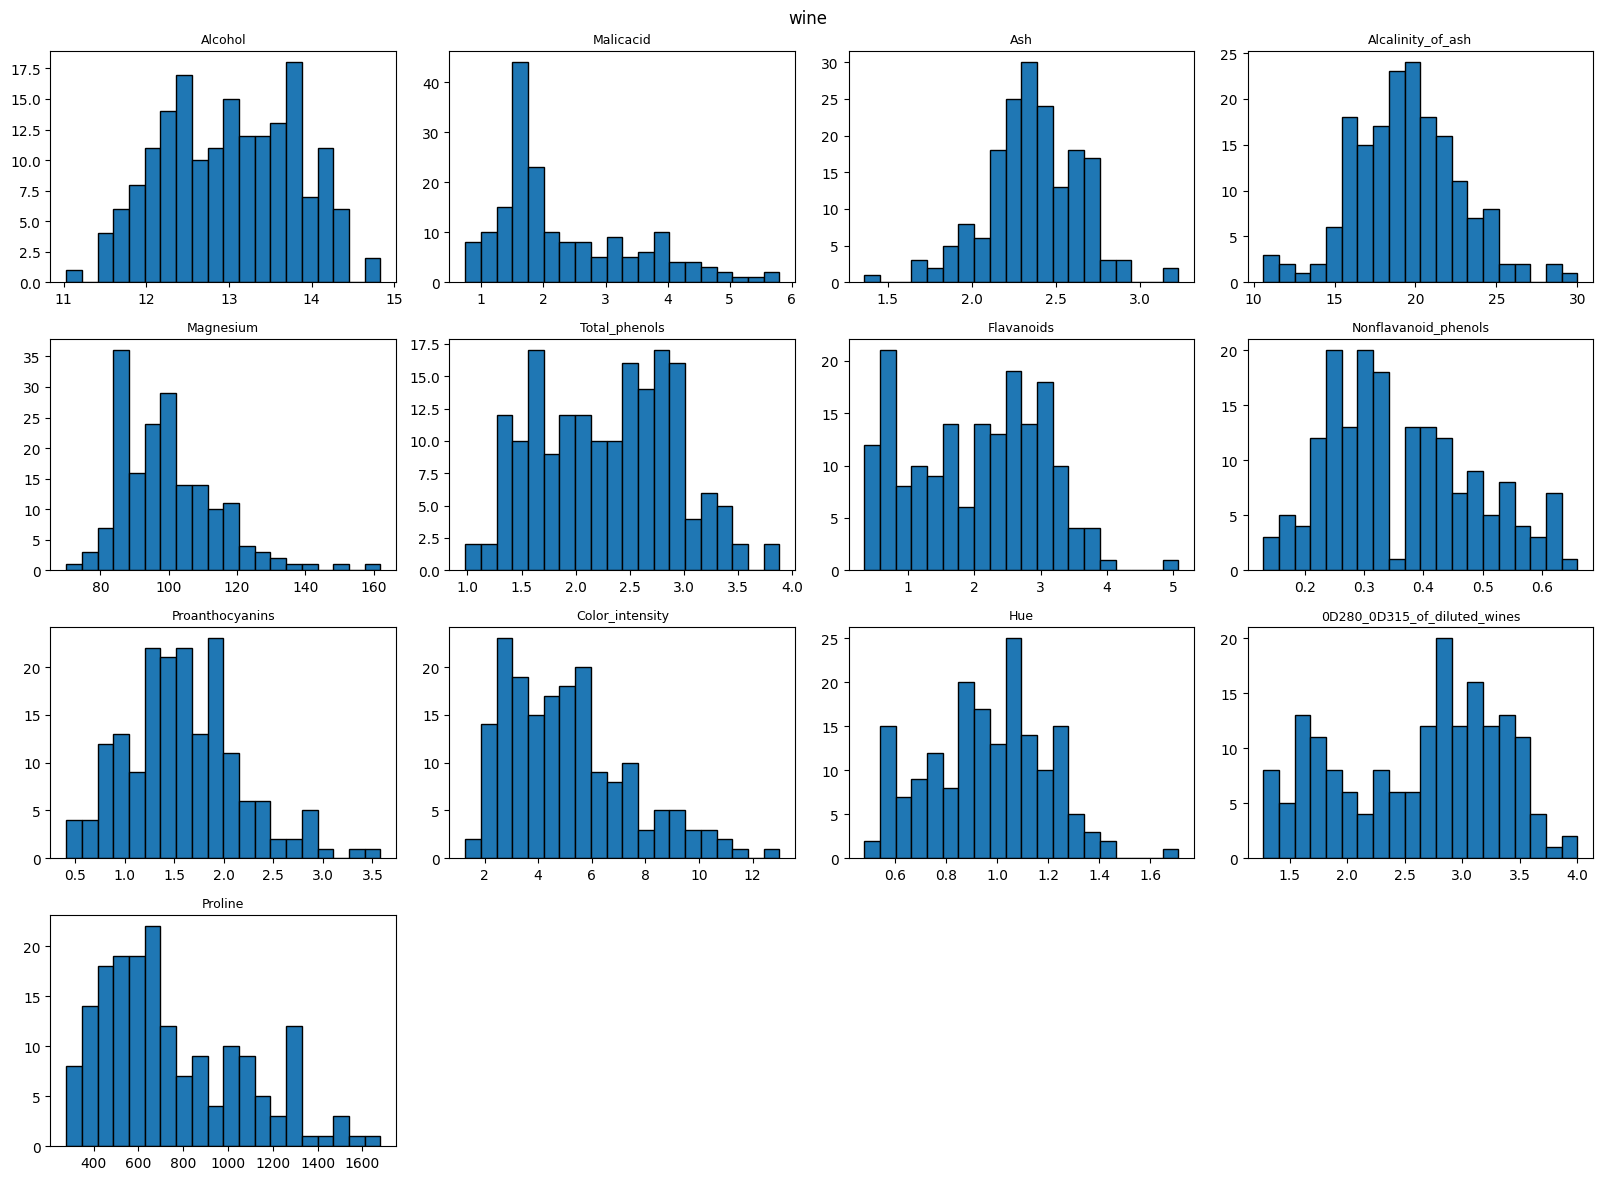

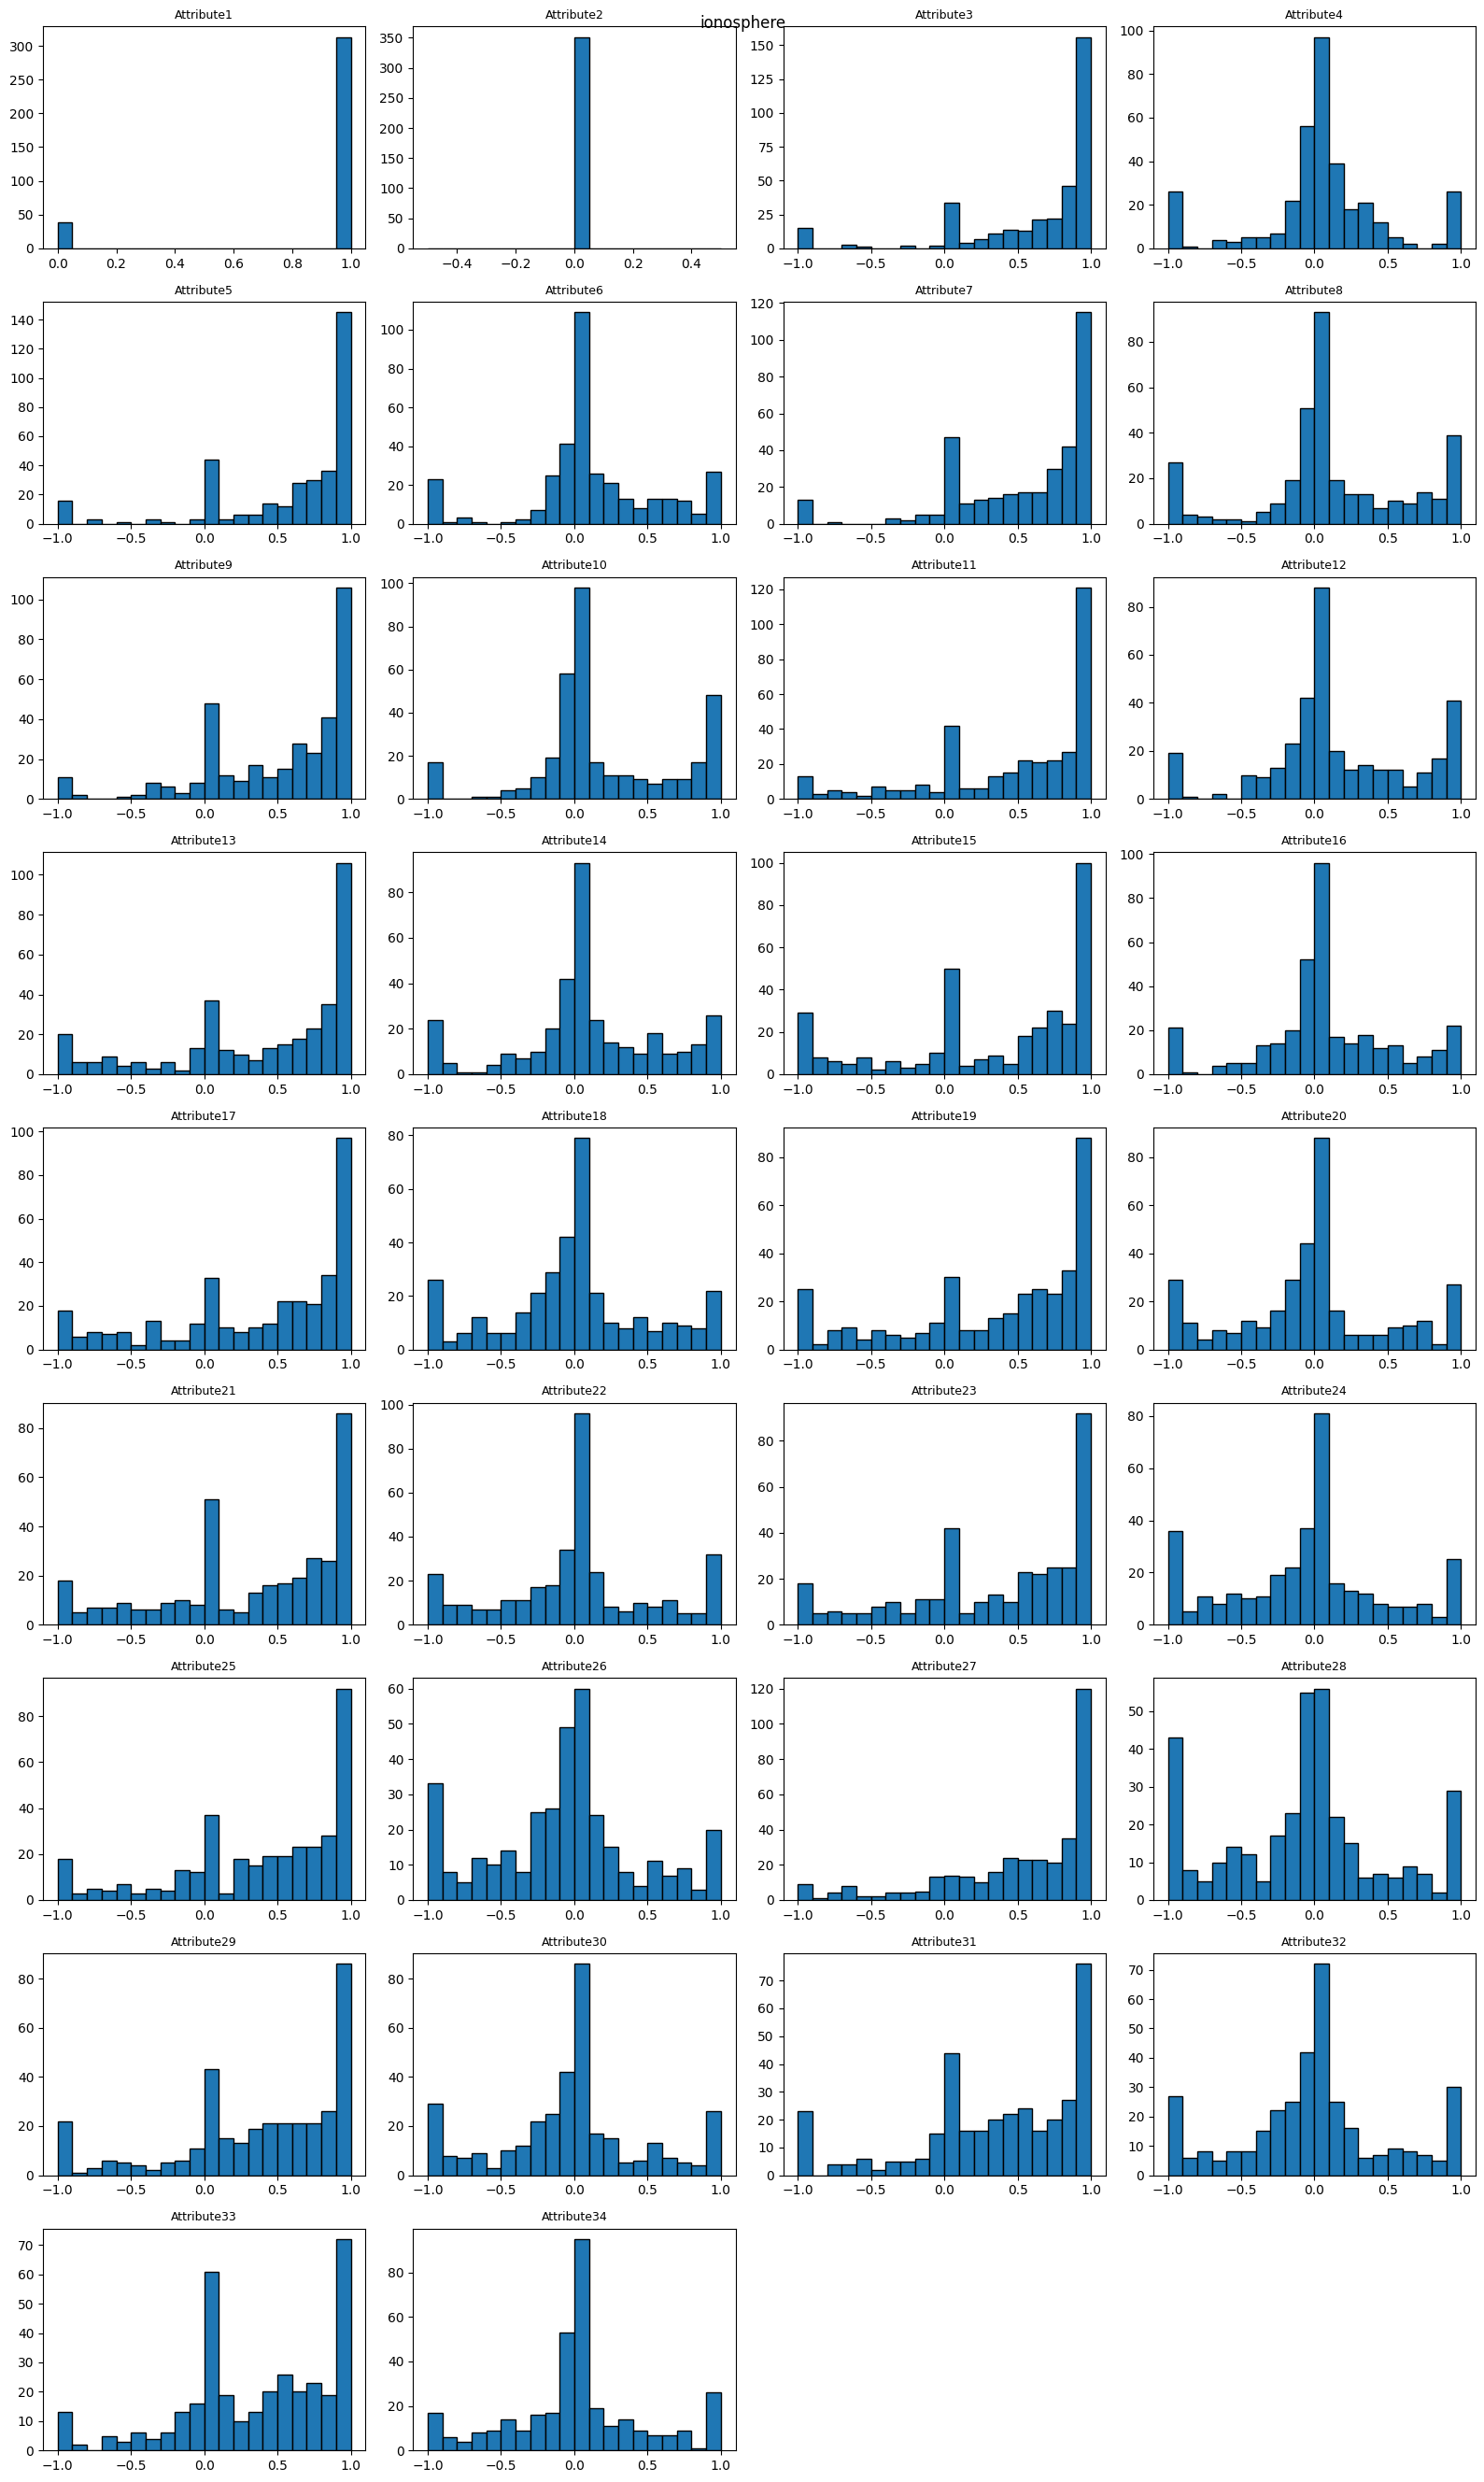

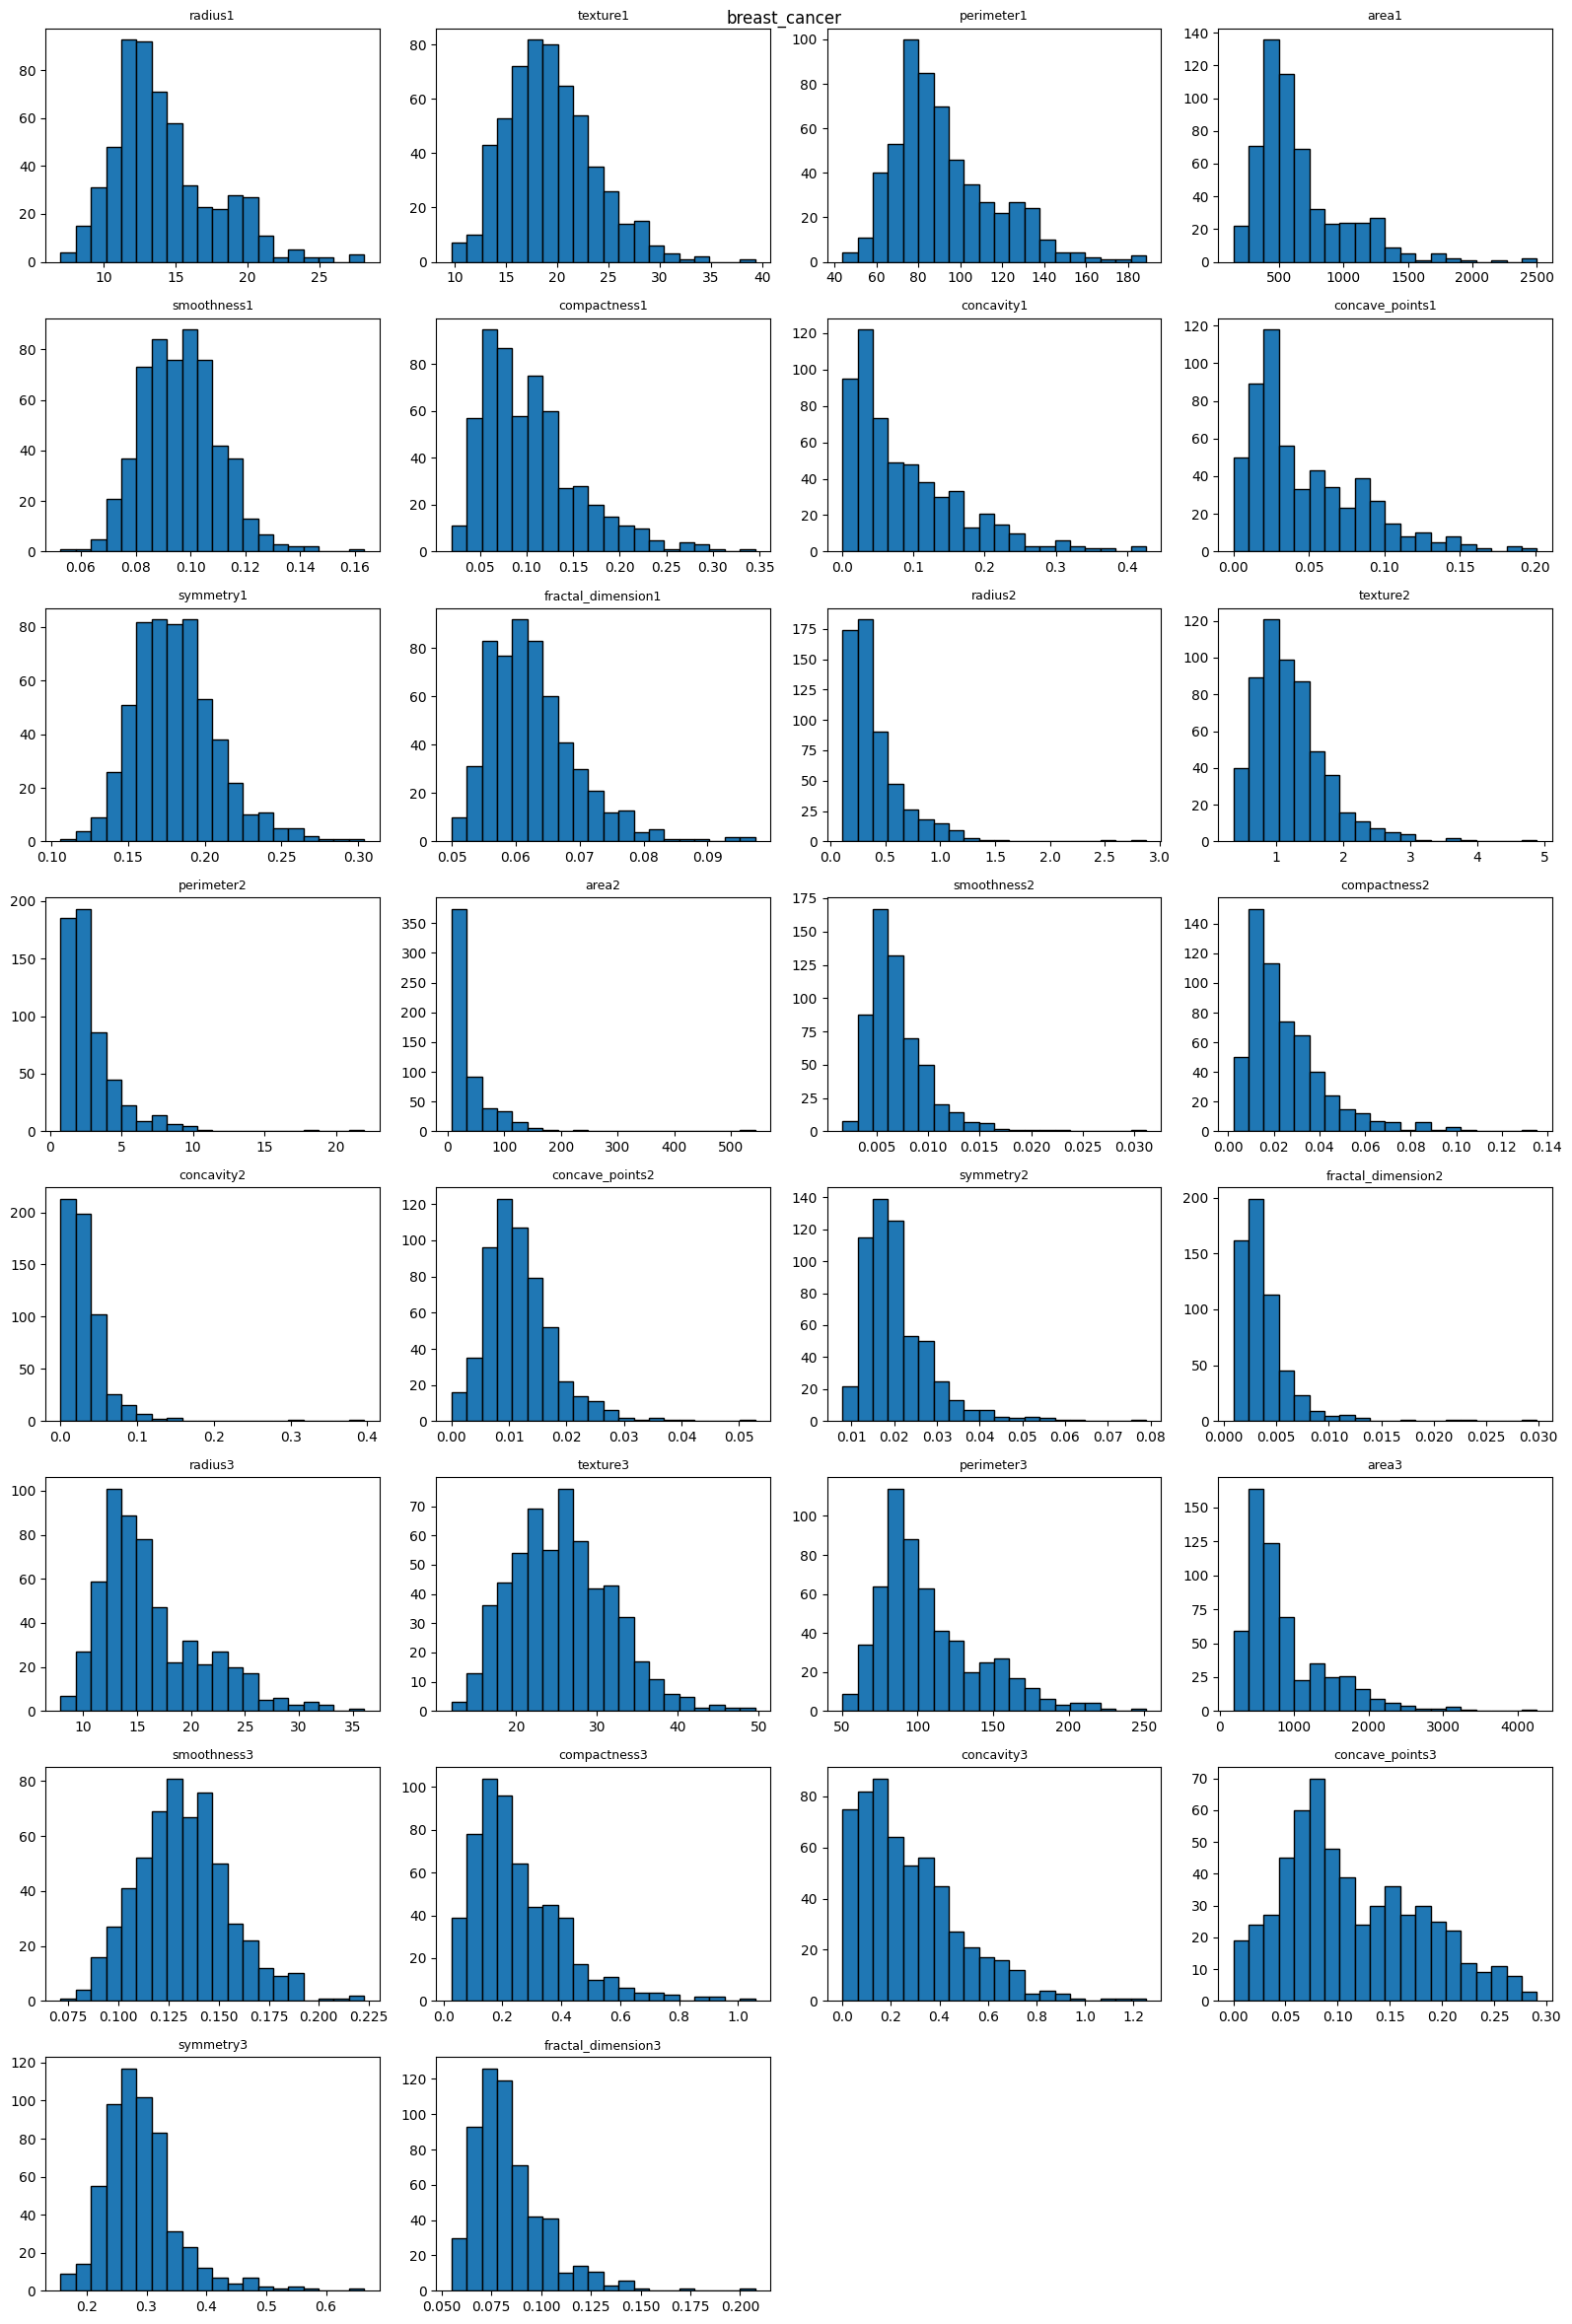

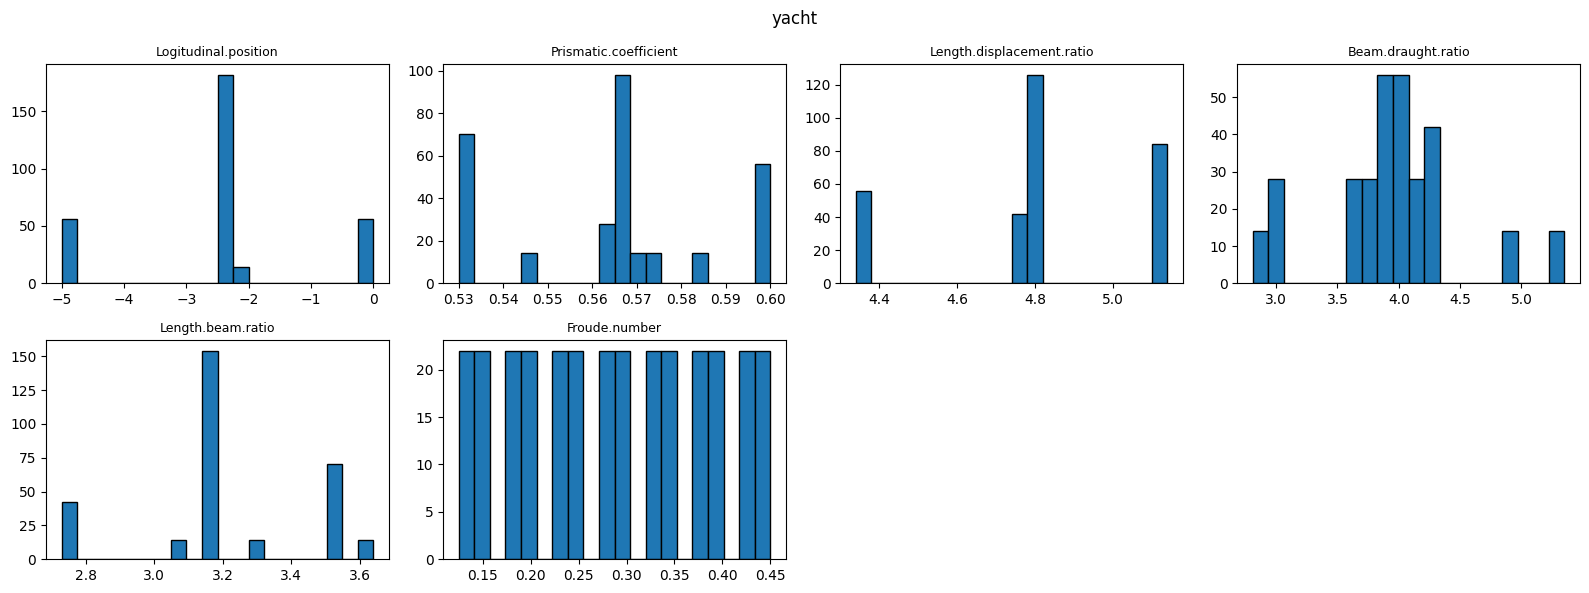

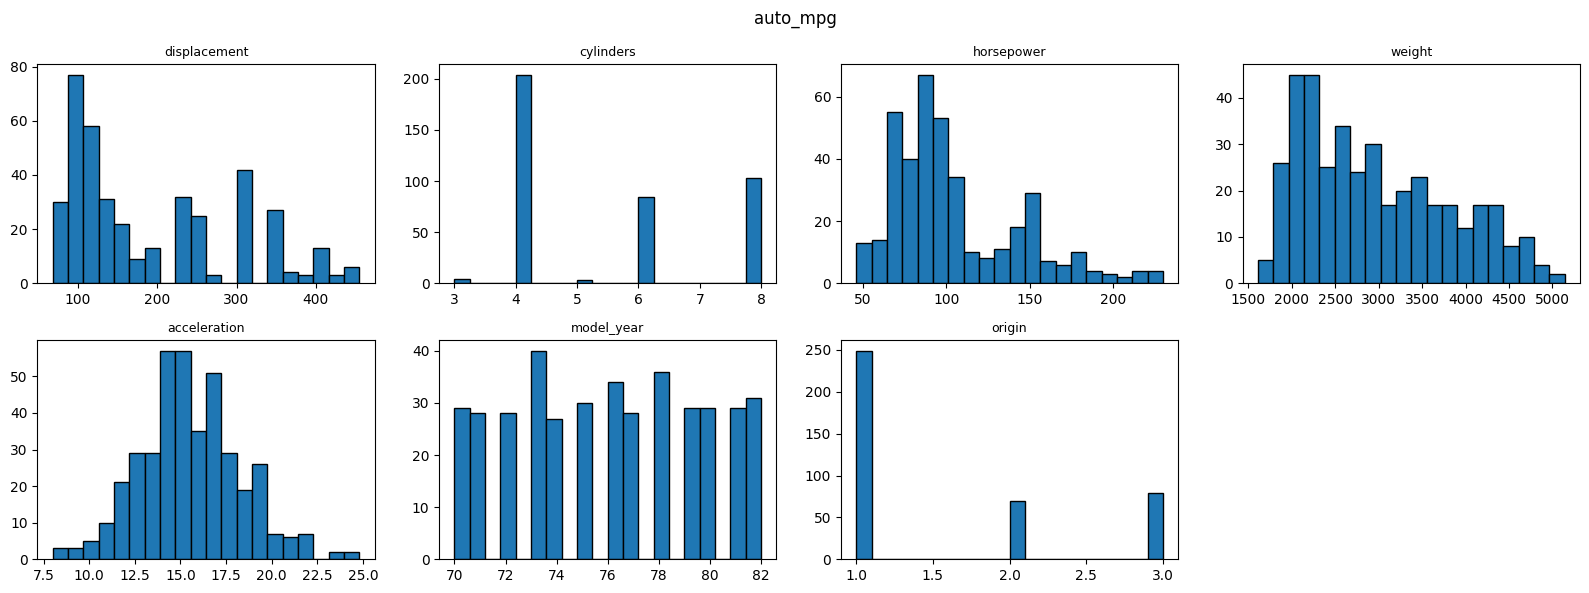

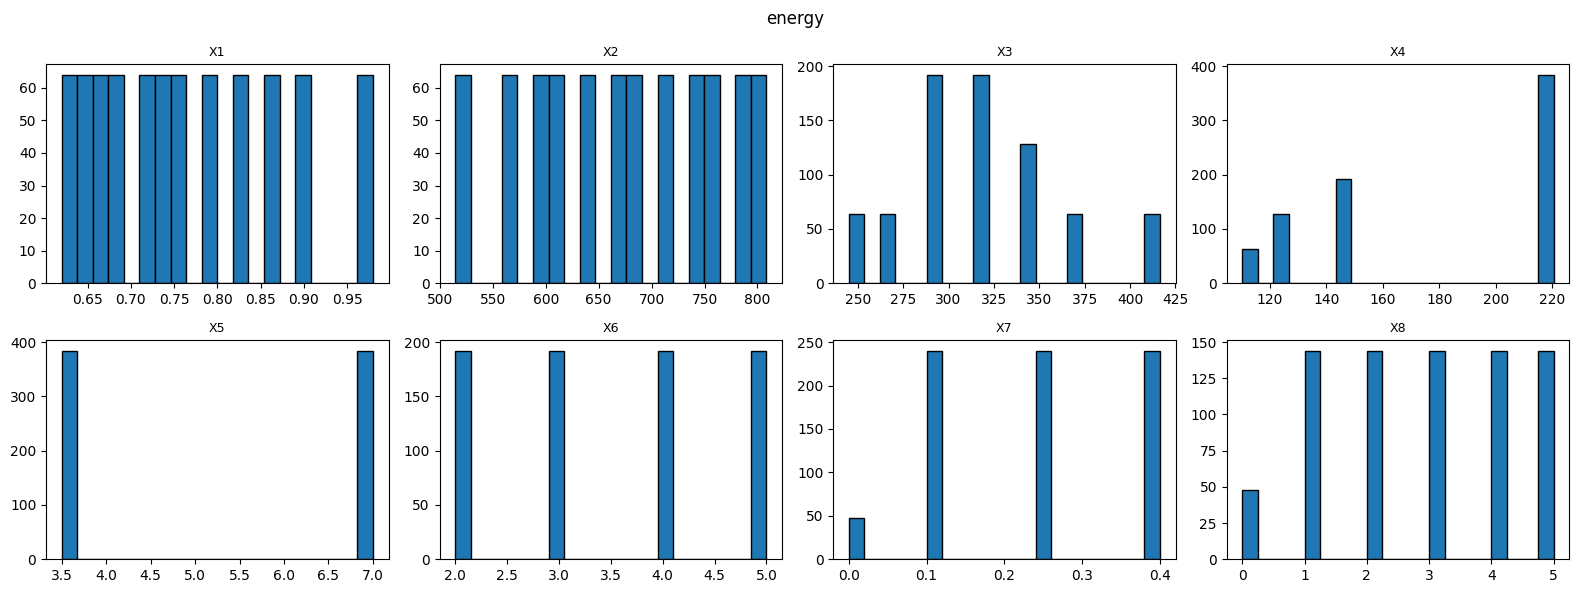

In [7]:
for key, ds in datasets.items():
    plot_histograms(key, ds.data.features)

In [8]:
dq_outliers = {}
for key, ds in datasets.items():
    dq_outliers[key] = gap_comparison_outliers(key, ds.data.features)

--- wine: gap-comparison ratios (no threshold applied — for ranking only) ---


,Feature,Max gap ratio,Min gap ratio
4,Magnesium,6.11,1.80
9,Color_intensity,4.50,1.32
3,Alcalinity_of_ash,4.25,2.87
8,Proanthocyanins,4.13,2.75
10,Hue,3.81,1.66
2,Ash,3.41,5.67
6,Flavanoids,2.98,0.93
5,Total_phenols,2.43,1.24
7,Nonflavanoid_phenols,2.28,2.00
1,Malicacid,2.23,3.29


--- ionosphere: gap-comparison ratios (no threshold applied — for ranking only) ---


,Feature,Max gap ratio,Min gap ratio
19,Attribute20,6.44,3.26
29,Attribute30,5.49,3.22
23,Attribute24,5.07,1.73
27,Attribute28,4.94,1.31
25,Attribute26,4.91,2.10
33,Attribute34,4.83,5.05
3,Attribute4,4.53,11.54
21,Attribute22,4.30,3.10
17,Attribute18,4.12,3.43
31,Attribute32,4.00,3.12


--- breast_cancer: gap-comparison ratios (no threshold applied — for ranking only) ---


,Feature,Max gap ratio,Min gap ratio
13,area2,24.06,1.65
16,concavity2,21.90,1.40
19,fractal_dimension2,18.44,1.44
12,perimeter2,17.40,1.25
10,radius2,15.48,1.32
14,smoothness2,13.01,2.85
18,symmetry2,11.68,2.04
17,concave_points2,10.07,2.32
28,symmetry3,9.69,2.95
29,fractal_dimension3,9.59,1.91


... (2 outputs left out)

--- auto_mpg: gap-comparison ratios (no threshold applied — for ranking only) ---


,Feature,Max gap ratio,Min gap ratio
4,acceleration,4.55,3.48
2,horsepower,3.20,1.57
3,weight,1.90,1.05
0,displacement,1.70,0.82
5,model_year,1.00,1.00
6,origin,1.00,NaN
1,cylinders,0.00,NaN


--- energy: gap-comparison ratios (no threshold applied — for ranking only) ---


,Feature,Max gap ratio,Min gap ratio
2,X3,3.00,2.00
0,X1,1.88,0.93
7,X8,1.00,1.40
1,X2,1.00,1.36
5,X6,1.00,1.00
3,X4,0.00,0.71
6,X7,0.00,0.67
4,X5,0.00,0.00


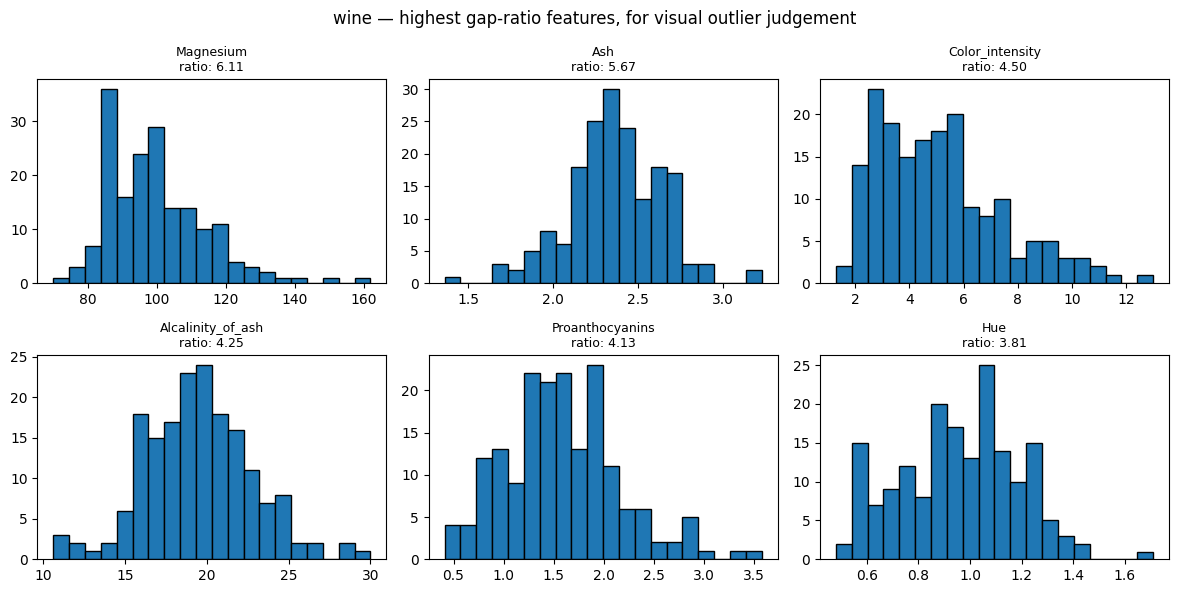

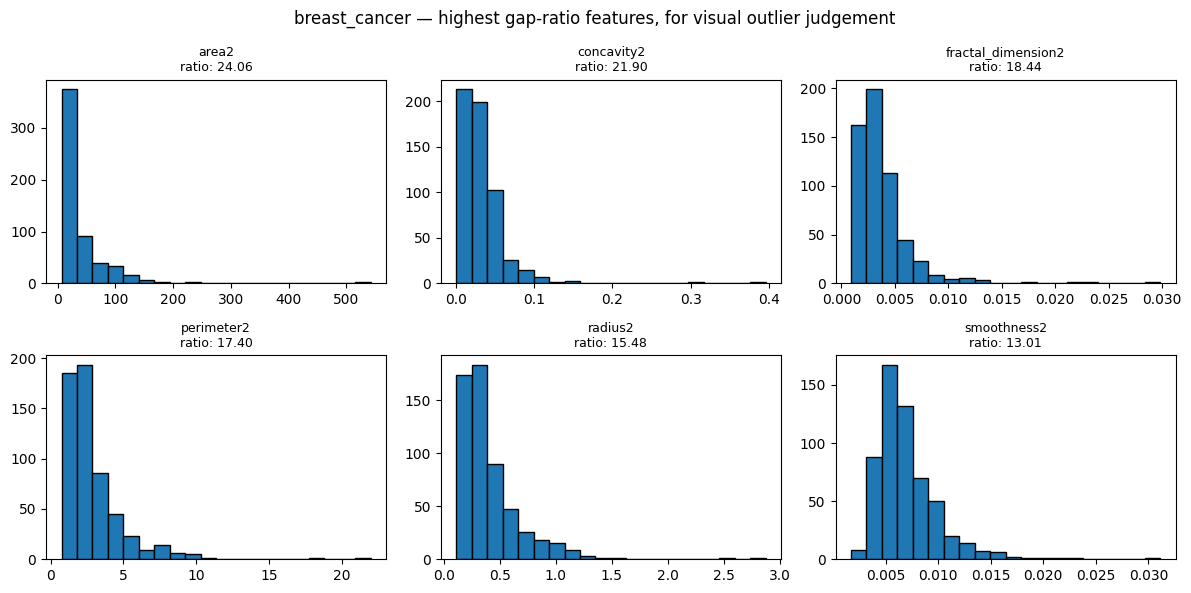

In [9]:
plot_top_ratio_histograms("wine", datasets["wine"].data.features, dq_outliers["wine"])
plot_top_ratio_histograms("breast_cancer", datasets["breast_cancer"].data.features, dq_outliers["breast_cancer"])

In [10]:
for key in classification_keys:
    X = datasets[key].data.features
    y = datasets[key].data.targets
    loo_error = one_nn_loo_error(X, y)
    fisher_ratio = fisher_discriminant_ratio(X, y)
    print(f"--- {key} ---")
    print(f"1-NN leave-one-out error rate: {loo_error:.4f}")
    print(f"Max Fisher discriminant ratio (F1): {fisher_ratio:.4f}")
    print()

--- wine ---
1-NN leave-one-out error rate: 0.0449
Max Fisher discriminant ratio (F1): 3.3509

--- ionosphere ---
1-NN leave-one-out error rate: 0.1339
Max Fisher discriminant ratio (F1): 0.3071

--- breast_cancer ---
1-NN leave-one-out error rate: 0.0492
Max Fisher discriminant ratio (F1): 1.7026



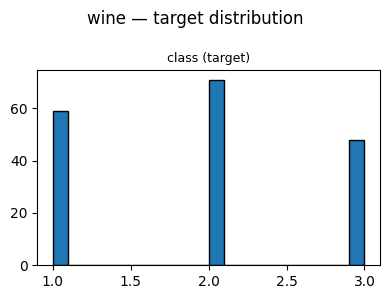

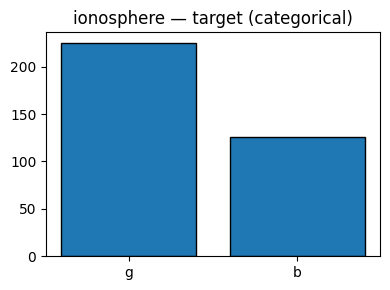

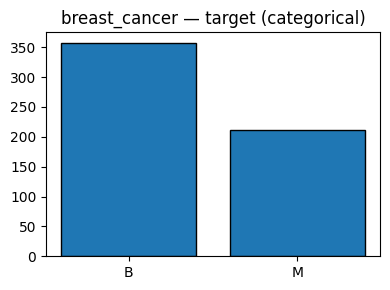

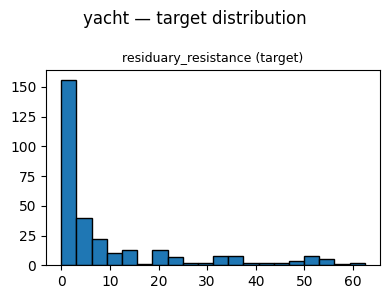

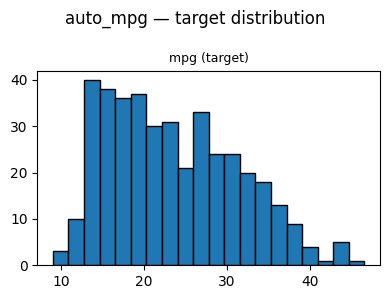

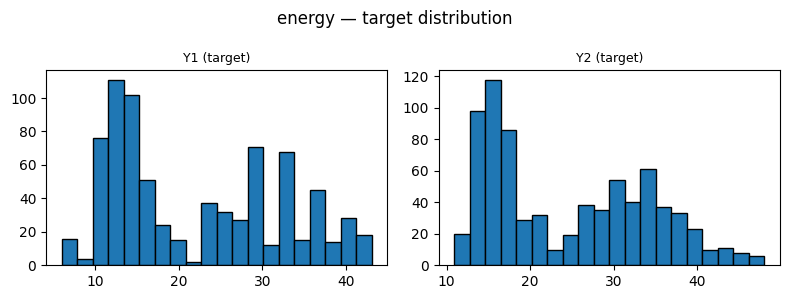

In [11]:
for key, ds in datasets.items():
    plot_target_histograms(key, ds.data.targets)

## Regression-specific checks

The classification complexity measures used above (1-NN leave-one-out
error, Fisher's discriminant ratio) rely on class labels and have no
direct equivalent for continuous targets, since the Ho and Basu (2002)
framework is specific to classification problems.

For the three regression datasets, structure, missingness, target
skewness, and outliers are checked the same way as for classification
(Cells 6, 8, and 9 already cover all six datasets). In addition, a
linearity check is run: a simple linear regression and a k-nearest
neighbours regressor are each evaluated with cross-validation, and their
R^2 scores are compared. A large gap, with the nonlinear model
outperforming the linear one, is evidence that the target is a genuinely
nonlinear function of the inputs, which is directly relevant to your
network's ability to learn it and worth reporting as evidence rather than
assumed from a dataset's general reputation.

In [12]:
regression_keys = ["yacht", "auto_mpg", "energy"]

for key in regression_keys:
    X = datasets[key].data.features
    y = datasets[key].data.targets
    lin_r2, knn_r2 = linearity_check(X, y)
    print(f"--- {key} ---")
    print(f"Linear regression R^2 (cross-validated): {lin_r2:.4f}")
    print(f"5-NN regression R^2 (cross-validated): {knn_r2:.4f}")
    print(f"Gap (KNN - Linear): {knn_r2 - lin_r2:.4f}")
    print()

--- yacht ---
Linear regression R^2 (cross-validated): 0.6496
5-NN regression R^2 (cross-validated): 0.7715
Gap (KNN - Linear): 0.1219

--- auto_mpg ---
Linear regression R^2 (cross-validated): 0.5946
5-NN regression R^2 (cross-validated): 0.6857
Gap (KNN - Linear): 0.0911

--- energy ---
Linear regression R^2 (cross-validated): 0.8903
5-NN regression R^2 (cross-validated): 0.9050
Gap (KNN - Linear): 0.0147



## Choosing a single target for Energy Efficiency

Energy Efficiency provides two continuous targets from the same eight
building-shape features: Y1 (heating load) and Y2 (cooling load). Only one
function approximation problem is required from this dataset, so a single
target must be selected.

Y1 is the default single-target convention for this dataset when mirrored
on OpenML (data_id 1472, `default_target_attribute: y1`), which is one
reasonable basis for the choice. As a second, complexity-based check, the
linearity test used earlier (comparing cross-validated linear regression
against 5-NN regression, both on standardised features) is run separately
on Y1 and Y2. A larger gap between the two models is evidence of a more
nonlinear target, which is directly relevant to testing SGD, SCG, and
LeapFrog on a genuinely demanding function. The target used going forward
is chosen using both pieces of evidence together, and the choice is
stated explicitly rather

In [13]:
def linearity_check_single_target(X, y_series, cv=5):
    X_num = X.select_dtypes(include=np.number).dropna()
    y_arr = y_series.loc[X_num.index].values
    X_scaled = StandardScaler().fit_transform(X_num)

    lin_scores = cross_val_score(LinearRegression(), X_scaled, y_arr, cv=cv, scoring="r2")
    knn_scores = cross_val_score(KNeighborsRegressor(n_neighbors=5), X_scaled, y_arr, cv=cv, scoring="r2")

    return lin_scores.mean(), knn_scores.mean()

energy_X = datasets["energy"].data.features
energy_targets_full = datasets["energy"].data.targets  # both Y1 and Y2, before any column selection

for target_col in ["Y1", "Y2"]:
    lin_r2, knn_r2 = linearity_check_single_target(energy_X, energy_targets_full[target_col])
    print(f"--- Energy Efficiency: {target_col} ---")
    print(f"Linear regression R^2 (cross-validated): {lin_r2:.4f}")
    print(f"5-NN regression R^2 (cross-validated): {knn_r2:.4f}")
    print(f"Gap (KNN - Linear): {knn_r2 - lin_r2:.4f}")
    print()

--- Energy Efficiency: Y1 ---
Linear regression R^2 (cross-validated): 0.8903
5-NN regression R^2 (cross-validated): 0.9050
Gap (KNN - Linear): 0.0147

--- Energy Efficiency: Y2 ---
Linear regression R^2 (cross-validated): 0.8752
5-NN regression R^2 (cross-validated): 0.9209
Gap (KNN - Linear): 0.0456



## Choosing a single target for Energy Efficiency

Energy Efficiency provides two continuous targets from the same eight
building-shape features: Y1 (heating load) and Y2 (cooling load). Only one
function approximation problem is required from this dataset, so a single
target must be selected.

Y1 is the default single-target convention for this dataset when mirrored
on OpenML (data_id 1472, `default_target_attribute: y1`), which is one
reasonable basis for the choice. As a second, complexity-based check, the
linearity test used earlier (comparing cross-validated linear regression
against 5-NN regression, both on standardised features) is run separately
on Y1 and Y2. A larger gap between the two models is evidence of a more
nonlinear target, which is directly relevant to testing SGD, SCG, and
LeapFrog on a genuinely demanding function.

Y2 showed a gap roughly three times larger than Y1 (0.0456 versus
0.0147), indicating a more nonlinear relationship to the input features.
Since the training algorithms under comparison are being tested
specifically on their ability to handle nonlinear optimisation, this
complexity evidence was prioritised over the OpenML default, and Y2 was
selected as the single regression target for Energy Efficiency going
forward.

In [14]:
datasets["energy"].data.targets = datasets["energy"].data.targets[["Y2"]]
print("Energy Efficiency target locked to:", datasets["energy"].data.targets.columns.tolist())

Energy Efficiency target locked to: ['Y2']


## Data Quality Report

Per Topic 2, a Data Quality Report is built for each dataset: a summary
statistics table for continuous features, and for classification
datasets, the same for the categorical target. This complements the
checks already run (structure, class balance, skewness via histogram,
gap-comparison outliers, separability, linearity) with the standard
tabular format taught in the course.

A correlation matrix is also computed for each dataset's continuous
features. This is not explicitly applied to these datasets in the
slides, but follows directly from the "Measuring Covariance and
Correlation" section of the same topic, and is included here because
feature redundancy is directly relevant to the hidden-unit architecture
decisions made later in the assignment.

In [15]:
def data_quality_report_continuous(name, X):
    numeric = X.select_dtypes(include=np.number)
    report = pd.DataFrame({
        "Count": numeric.count(),
        "% Miss.": (numeric.isnull().sum() / len(numeric) * 100).round(1),
        "Card.": numeric.nunique(),
        "Min.": numeric.min(),
        "1st Qrt.": numeric.quantile(0.25),
        "Mean": numeric.mean(),
        "Median": numeric.median(),
        "3rd Qrt.": numeric.quantile(0.75),
        "Max.": numeric.max(),
        "Std. Dev.": numeric.std(),
    }).round(3)
    print(f"--- {name}: continuous features ---")
    display(report)
    return report

def data_quality_report_categorical(name, series, feature_name="target"):
    counts = series.value_counts()
    total = len(series)
    mode = counts.index[0] if len(counts) > 0 else None
    mode_freq = counts.iloc[0] if len(counts) > 0 else 0
    second_mode = counts.index[1] if len(counts) > 1 else None
    second_mode_freq = counts.iloc[1] if len(counts) > 1 else 0
    report = pd.DataFrame({
        "Feature": [feature_name],
        "Count": [series.count()],
        "% Miss.": [round(series.isnull().sum() / total * 100, 1)],
        "Card.": [series.nunique()],
        "Mode": [mode],
        "Mode Freq.": [mode_freq],
        "Mode %": [round(mode_freq / total * 100, 1)],
        "2nd Mode": [second_mode],
        "2nd Mode Freq.": [second_mode_freq],
        "2nd Mode %": [round(second_mode_freq / total * 100, 1) if second_mode is not None else None],
    })
    print(f"--- {name}: categorical features ---")
    display(report)
    return report

def correlation_heatmap(name, X):
    numeric = X.select_dtypes(include=np.number)
    corr = numeric.corr()
    fig, ax = plt.subplots(figsize=(0.6*len(corr.columns)+2, 0.6*len(corr.columns)+2))
    im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
    ax.set_xticks(range(len(corr.columns)))
    ax.set_yticks(range(len(corr.columns)))
    ax.set_xticklabels(corr.columns, rotation=90, fontsize=8)
    ax.set_yticklabels(corr.columns, fontsize=8)
    fig.colorbar(im)
    ax.set_title(f"{name} — feature correlation")
    plt.tight_layout()
    plt.show()

--- wine: continuous features ---


,Count,% Miss.,Card.,Min.,1st Qrt.,Mean,Median,3rd Qrt.,Max.,Std. Dev.
Alcohol,178,0.0,126,11.03,12.362,13.001,13.050,13.678,14.83,0.812
Malicacid,178,0.0,133,0.74,1.602,2.336,1.865,3.082,5.80,1.117
Ash,178,0.0,79,1.36,2.210,2.367,2.360,2.558,3.23,0.274
Alcalinity_of_ash,178,0.0,63,10.60,17.200,19.495,19.500,21.500,30.00,3.340
Magnesium,178,0.0,53,70.00,88.000,99.742,98.000,107.000,162.00,14.282
Total_phenols,178,0.0,97,0.98,1.742,2.295,2.355,2.800,3.88,0.626
Flavanoids,178,0.0,132,0.34,1.205,2.029,2.135,2.875,5.08,0.999
Nonflavanoid_phenols,178,0.0,39,0.13,0.270,0.362,0.340,0.438,0.66,0.124
Proanthocyanins,178,0.0,101,0.41,1.250,1.591,1.555,1.950,3.58,0.572
Color_intensity,178,0.0,132,1.28,3.220,5.058,4.690,6.200,13.00,2.318


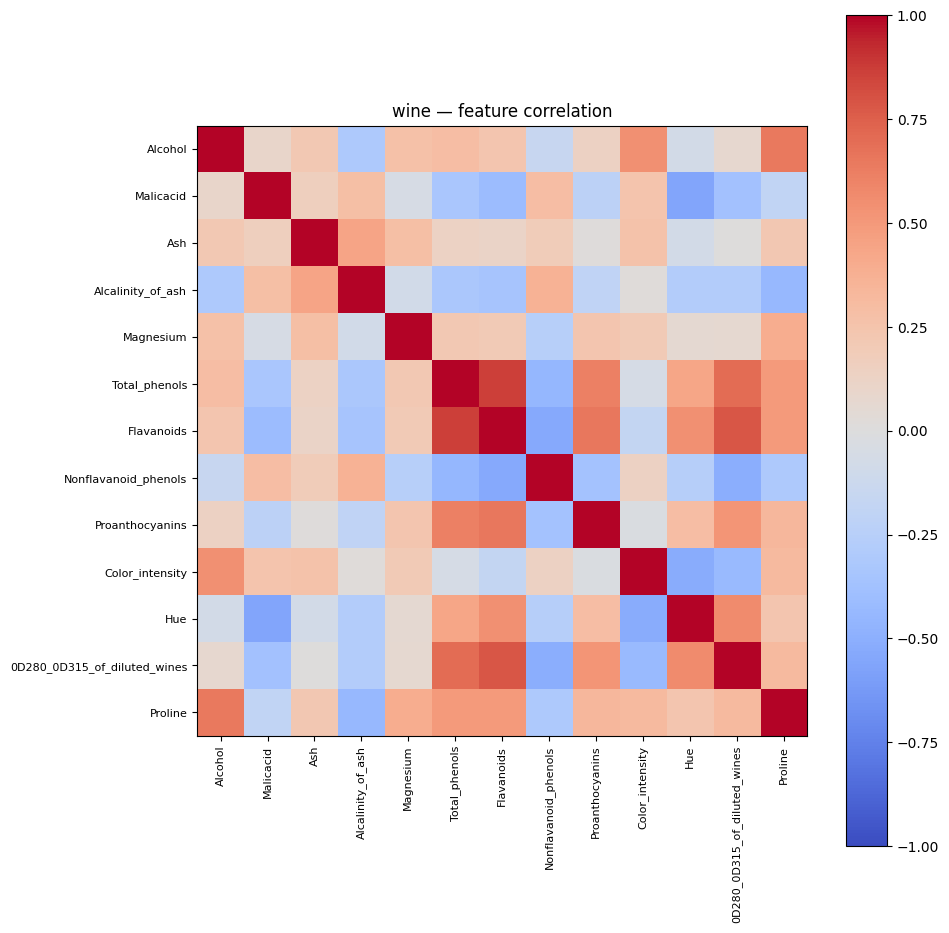

--- ionosphere: continuous features ---


,Count,% Miss.,Card.,Min.,1st Qrt.,Mean,Median,3rd Qrt.,Max.,Std. Dev.
Attribute1,351,0.0,2,0.0,1.000,0.892,1.000,1.000,1.0,0.311
Attribute2,351,0.0,1,0.0,0.000,0.000,0.000,0.000,0.0,0.000
Attribute3,351,0.0,219,-1.0,0.472,0.641,0.871,1.000,1.0,0.498
Attribute4,351,0.0,269,-1.0,-0.065,0.044,0.016,0.194,1.0,0.441
Attribute5,351,0.0,204,-1.0,0.413,0.601,0.809,1.000,1.0,0.520
Attribute6,351,0.0,259,-1.0,-0.025,0.116,0.023,0.335,1.0,0.461
Attribute7,351,0.0,231,-1.0,0.211,0.550,0.729,0.969,1.0,0.493
Attribute8,351,0.0,260,-1.0,-0.055,0.119,0.015,0.446,1.0,0.521
Attribute9,351,0.0,244,-1.0,0.087,0.512,0.684,0.953,1.0,0.507
Attribute10,351,0.0,267,-1.0,-0.048,0.181,0.018,0.534,1.0,0.484


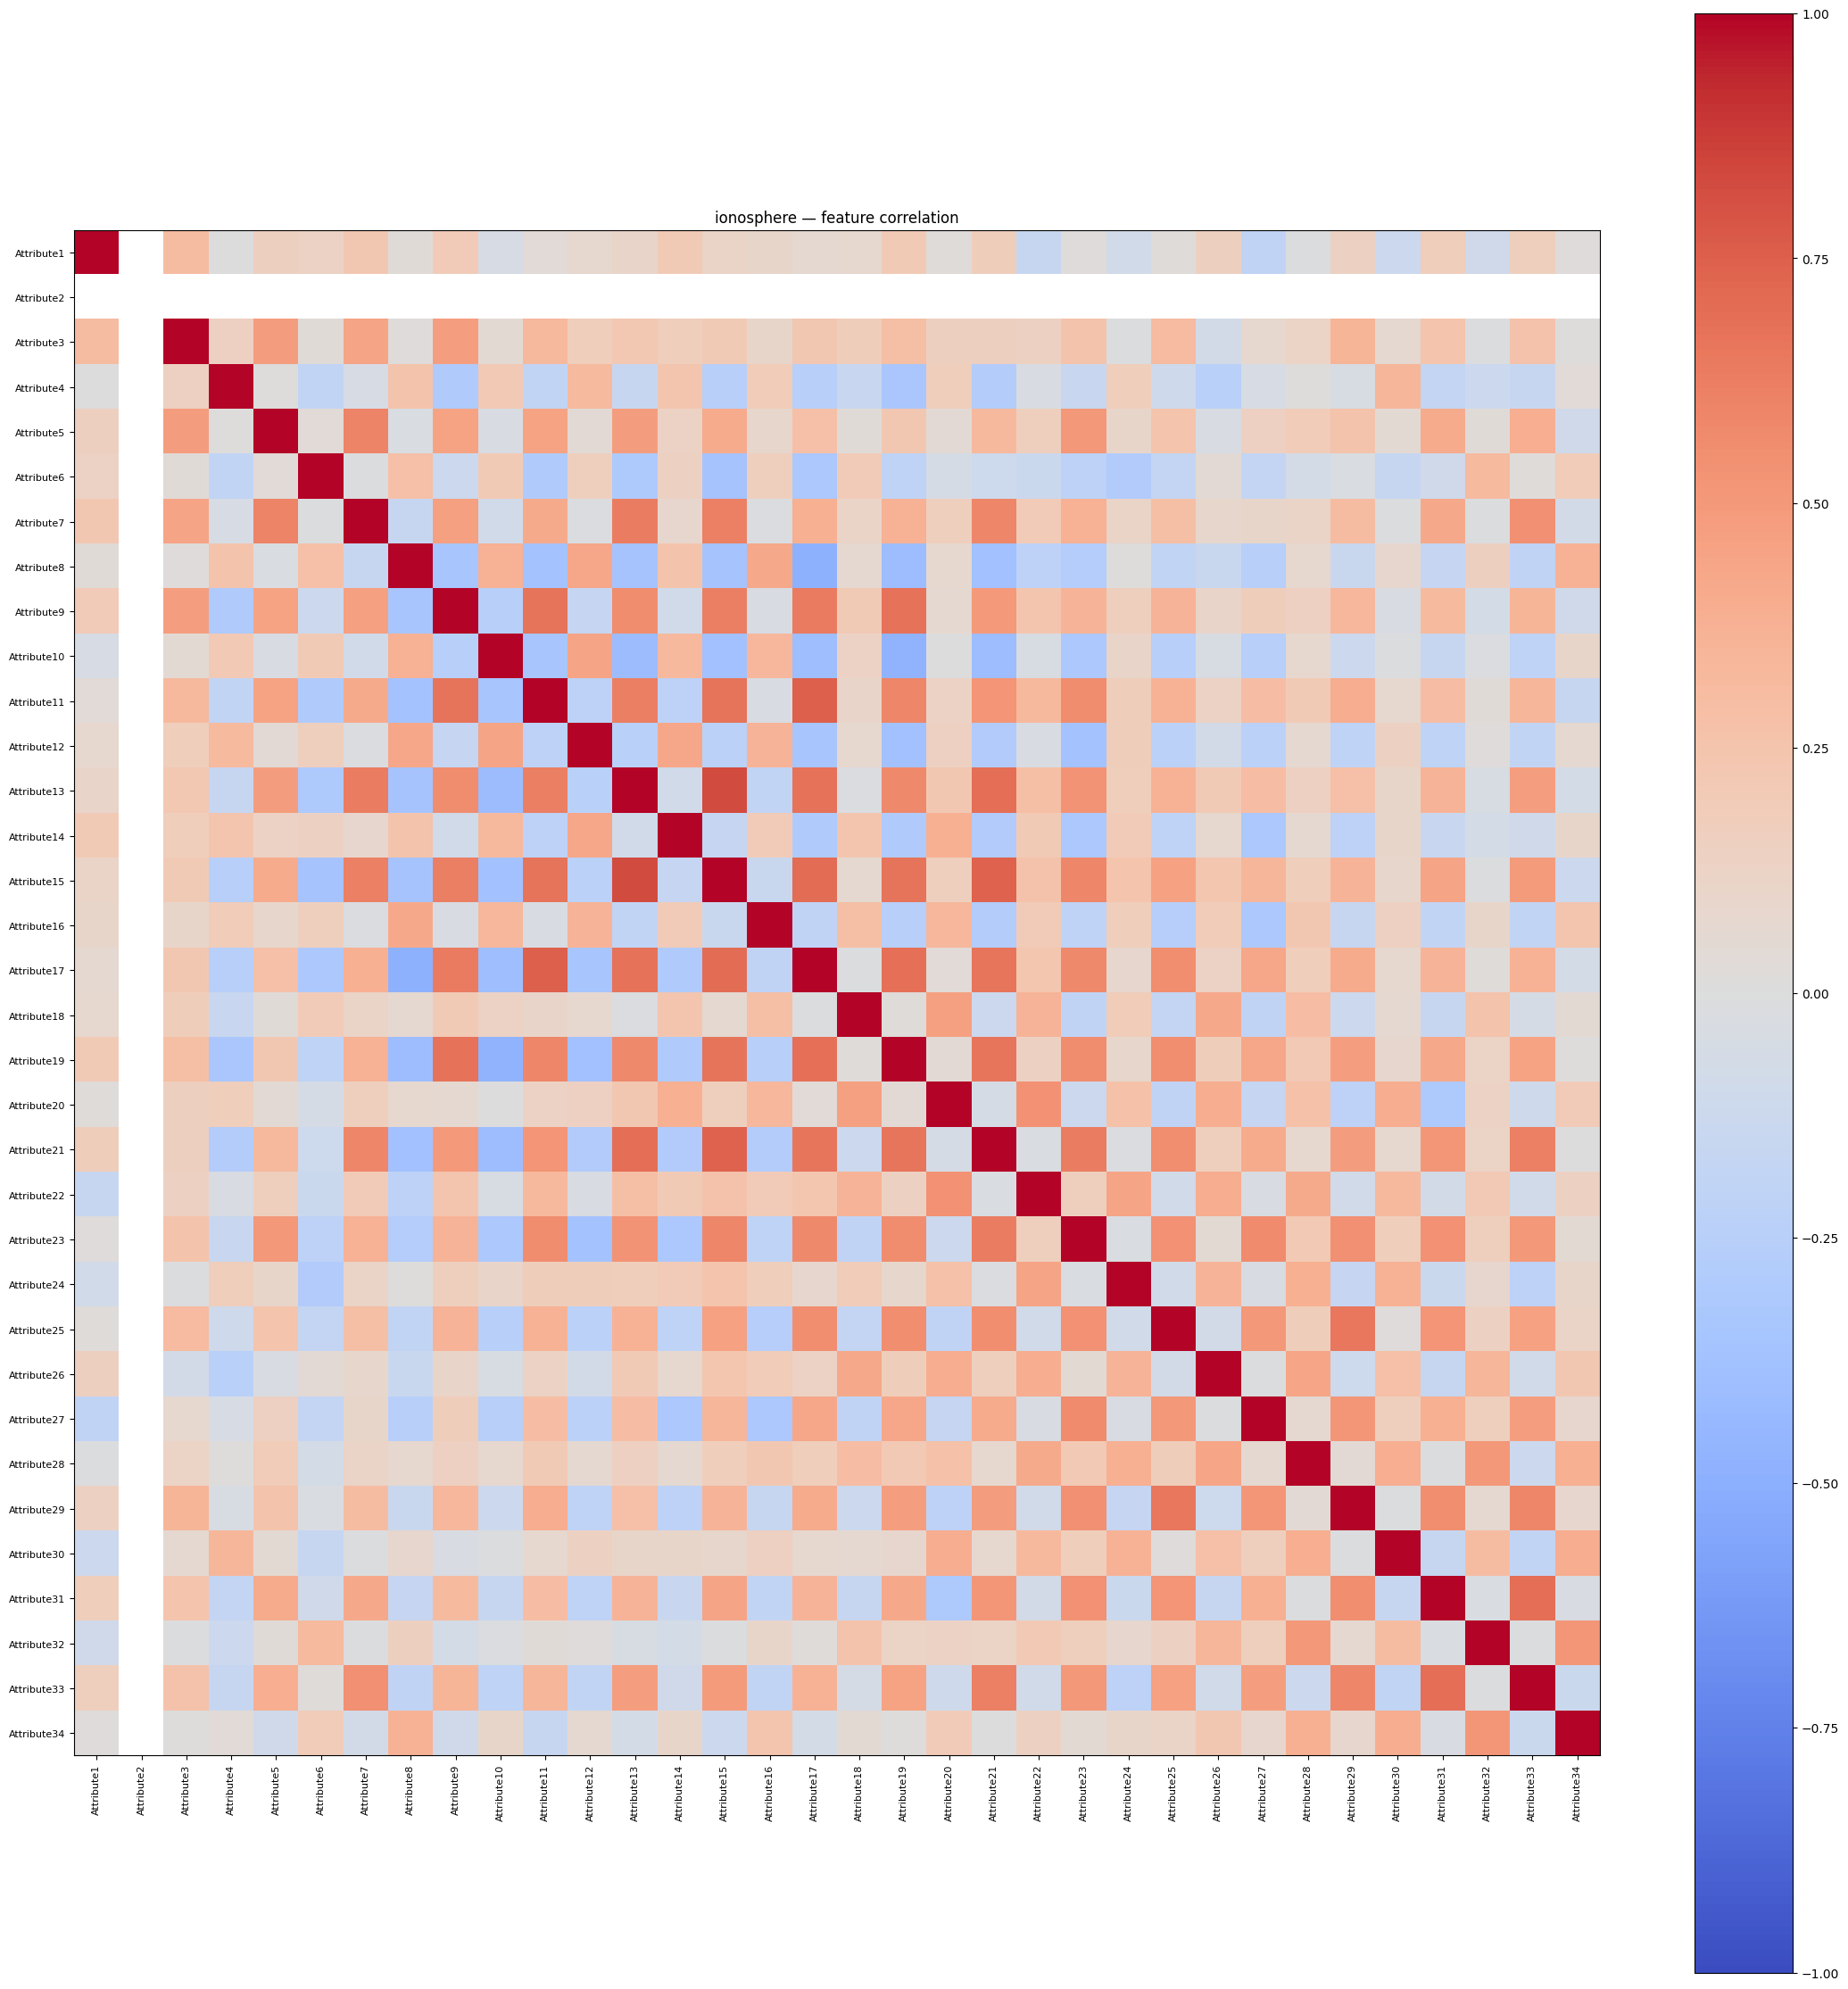

--- breast_cancer: continuous features ---


,Count,% Miss.,Card.,Min.,1st Qrt.,Mean,Median,3rd Qrt.,Max.,Std. Dev.
radius1,569,0.0,456,6.981,11.700,14.127,13.370,15.780,28.110,3.524
texture1,569,0.0,479,9.710,16.170,19.290,18.840,21.800,39.280,4.301
perimeter1,569,0.0,522,43.790,75.170,91.969,86.240,104.100,188.500,24.299
area1,569,0.0,539,143.500,420.300,654.889,551.100,782.700,2501.000,351.914
smoothness1,569,0.0,474,0.053,0.086,0.096,0.096,0.105,0.163,0.014
compactness1,569,0.0,537,0.019,0.065,0.104,0.093,0.130,0.345,0.053
concavity1,569,0.0,537,0.000,0.030,0.089,0.062,0.131,0.427,0.080
concave_points1,569,0.0,542,0.000,0.020,0.049,0.034,0.074,0.201,0.039
symmetry1,569,0.0,432,0.106,0.162,0.181,0.179,0.196,0.304,0.027
fractal_dimension1,569,0.0,499,0.050,0.058,0.063,0.062,0.066,0.097,0.007


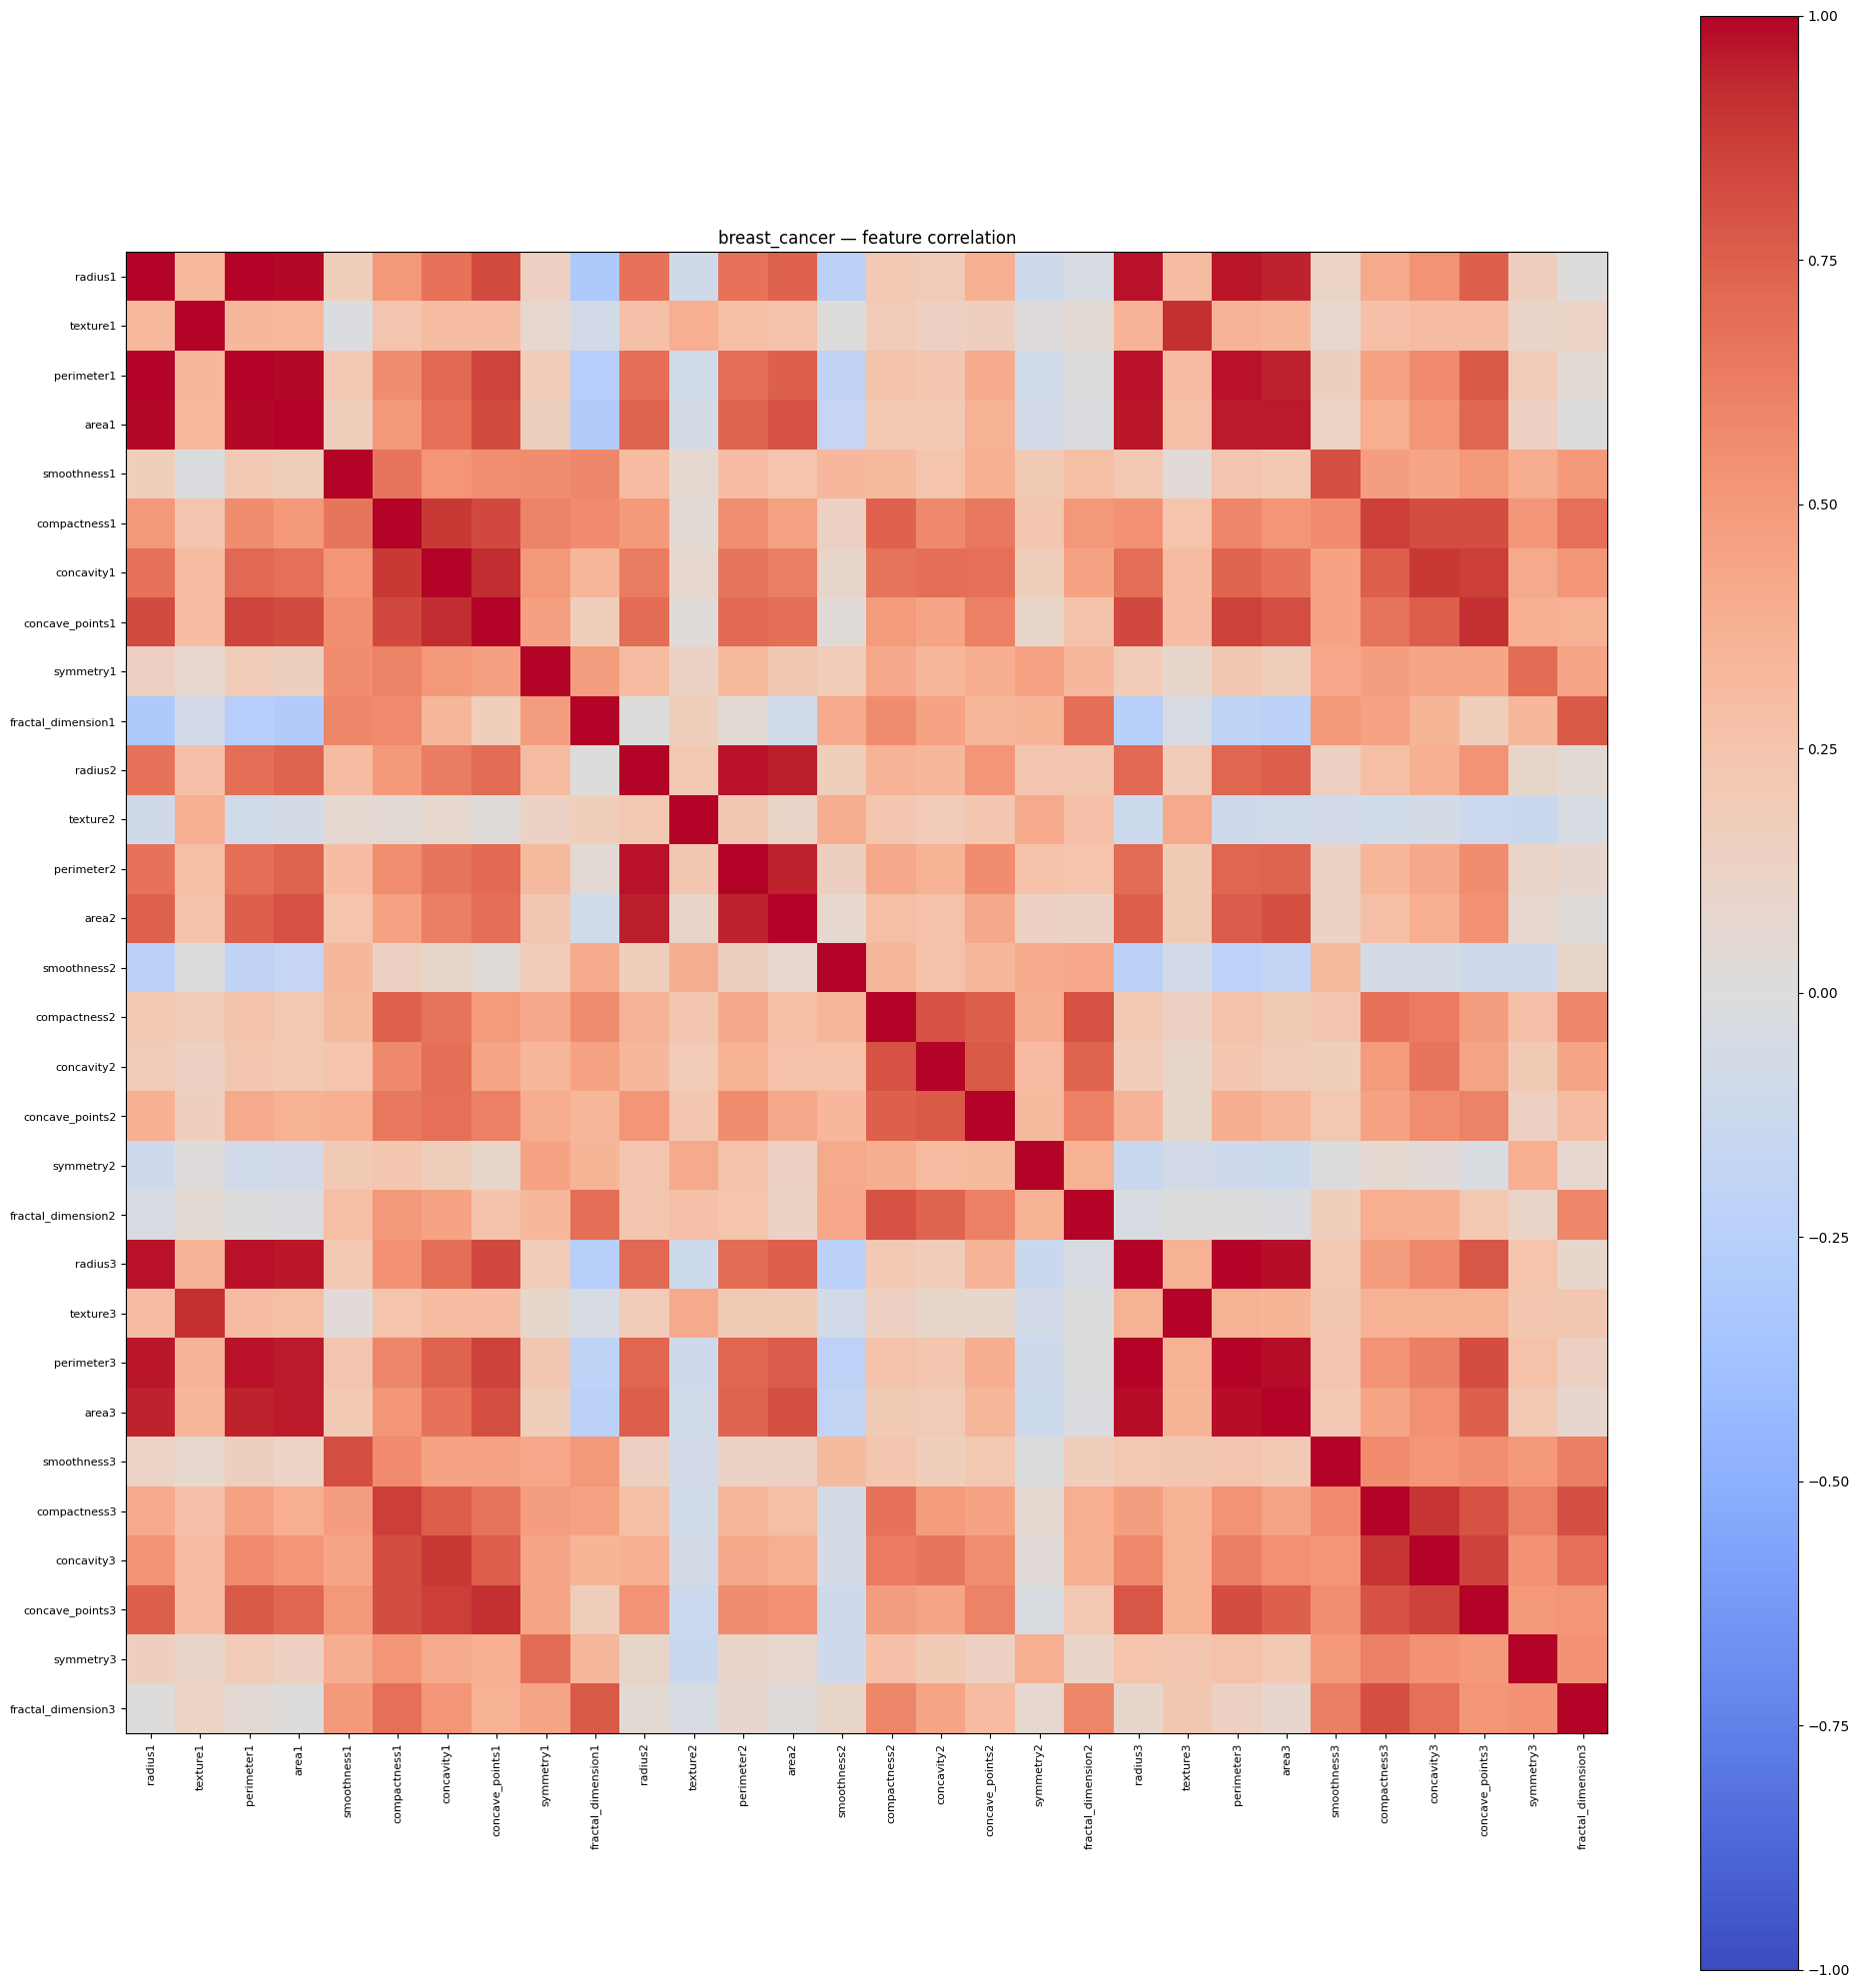

--- yacht: continuous features ---


,Count,% Miss.,Card.,Min.,1st Qrt.,Mean,Median,3rd Qrt.,Max.,Std. Dev.
Logitudinal.position,308,0.0,5,-5.000,-2.400,-2.382,-2.300,-2.300,0.00,1.513
Prismatic.coefficient,308,0.0,10,0.530,0.546,0.564,0.565,0.574,0.60,0.023
Length.displacement.ratio,308,0.0,8,4.340,4.770,4.789,4.780,5.100,5.14,0.253
Beam.draught.ratio,308,0.0,17,2.810,3.750,3.937,3.955,4.170,5.35,0.548
Length.beam.ratio,308,0.0,10,2.730,3.150,3.207,3.150,3.510,3.64,0.248
Froude.number,308,0.0,14,0.125,0.200,0.288,0.288,0.375,0.45,0.101


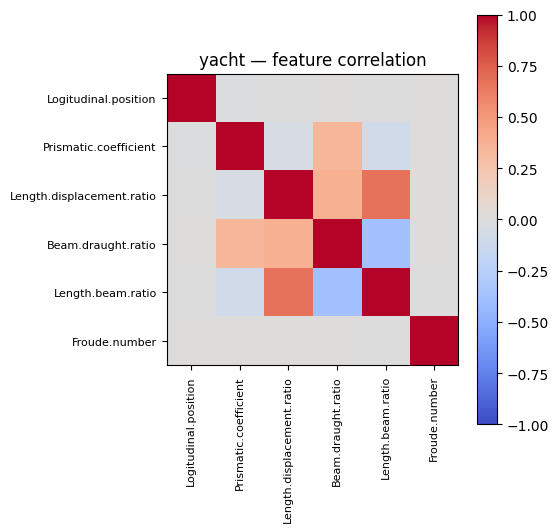

--- auto_mpg: continuous features ---


,Count,% Miss.,Card.,Min.,1st Qrt.,Mean,Median,3rd Qrt.,Max.,Std. Dev.
displacement,398,0.0,82,68.0,104.250,193.426,148.5,262.000,455.0,104.270
cylinders,398,0.0,5,3.0,4.000,5.455,4.0,8.000,8.0,1.701
horsepower,392,1.5,93,46.0,75.000,104.469,93.5,126.000,230.0,38.491
weight,398,0.0,351,1613.0,2223.750,2970.425,2803.5,3608.000,5140.0,846.842
acceleration,398,0.0,95,8.0,13.825,15.568,15.5,17.175,24.8,2.758
model_year,398,0.0,13,70.0,73.000,76.010,76.0,79.000,82.0,3.698
origin,398,0.0,3,1.0,1.000,1.573,1.0,2.000,3.0,0.802


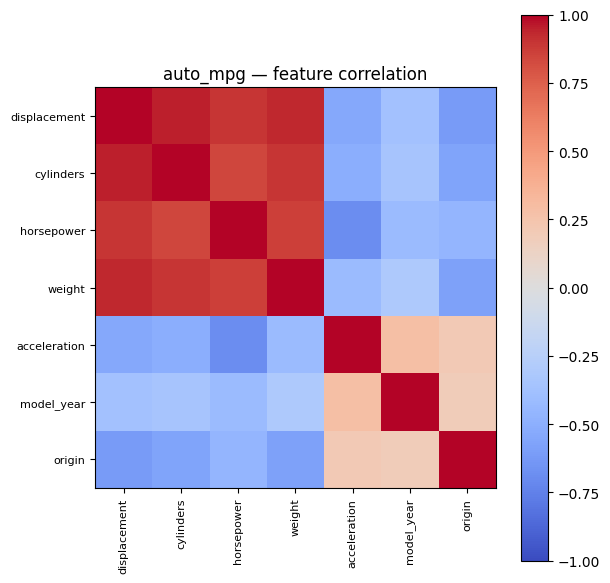

--- energy: continuous features ---


,Count,% Miss.,Card.,Min.,1st Qrt.,Mean,Median,3rd Qrt.,Max.,Std. Dev.
X1,768,0.0,12,0.62,0.682,0.764,0.75,0.830,0.98,0.106
X2,768,0.0,12,514.50,606.375,671.708,673.75,741.125,808.50,88.086
X3,768,0.0,7,245.00,294.000,318.500,318.50,343.000,416.50,43.626
X4,768,0.0,4,110.25,140.875,176.604,183.75,220.500,220.50,45.166
X5,768,0.0,2,3.50,3.500,5.250,5.25,7.000,7.00,1.751
X6,768,0.0,4,2.00,2.750,3.500,3.50,4.250,5.00,1.119
X7,768,0.0,4,0.00,0.100,0.234,0.25,0.400,0.40,0.133
X8,768,0.0,6,0.00,1.750,2.812,3.00,4.000,5.00,1.551


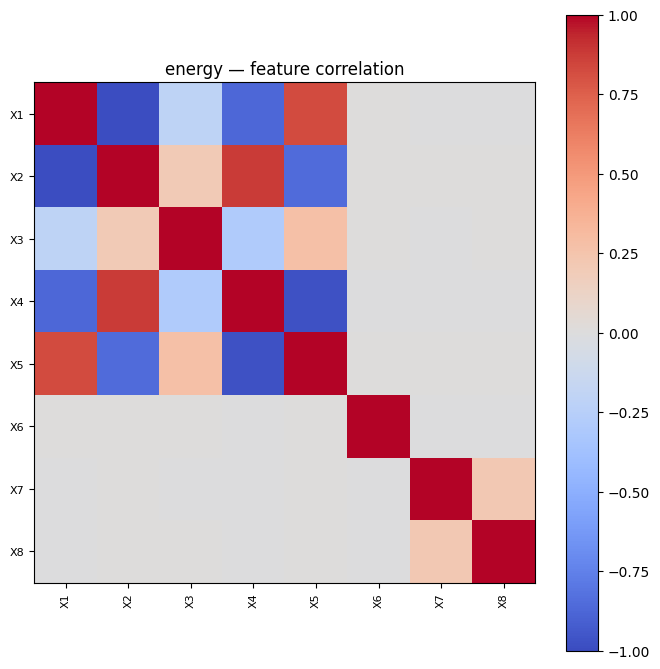

--- wine: categorical features ---


,Feature,Count,% Miss.,Card.,Mode,Mode Freq.,Mode %,2nd Mode,2nd Mode Freq.,2nd Mode %
0,target,178,0.0,3,2,71,39.9,1,59,33.1


--- ionosphere: categorical features ---


,Feature,Count,% Miss.,Card.,Mode,Mode Freq.,Mode %,2nd Mode,2nd Mode Freq.,2nd Mode %
0,target,351,0.0,2,g,225,64.1,b,126,35.9


--- breast_cancer: categorical features ---


,Feature,Count,% Miss.,Card.,Mode,Mode Freq.,Mode %,2nd Mode,2nd Mode Freq.,2nd Mode %
0,target,569,0.0,2,B,357,62.7,M,212,37.3


In [16]:
dq_continuous = {}
dq_categorical = {}

for key, ds in datasets.items():
    X = ds.data.features
    dq_continuous[key] = data_quality_report_continuous(key, X)
    correlation_heatmap(key, X)

for key in classification_keys:
    y_series = datasets[key].data.targets.iloc[:, 0]
    dq_categorical[key] = data_quality_report_categorical(key, y_series, feature_name="target")

In [17]:
def high_correlation_pairs(name, X, threshold=0.85):
    numeric = X.select_dtypes(include=np.number)
    corr = numeric.corr().abs()
    pairs = []
    cols = corr.columns
    for i in range(len(cols)):
        for j in range(i+1, len(cols)):
            r = corr.iloc[i, j]
            if r >= threshold:
                pairs.append({"Feature 1": cols[i], "Feature 2": cols[j], "Correlation": round(r, 3)})
    result = pd.DataFrame(pairs).sort_values("Correlation", ascending=False) if pairs else pd.DataFrame(columns=["Feature 1", "Feature 2", "Correlation"])
    print(f"--- {name}: feature pairs with |correlation| >= {threshold} ---")
    display(result)
    return result

dq_correlation = {}
for key, ds in datasets.items():
    dq_correlation[key] = high_correlation_pairs(key, ds.data.features)

--- wine: feature pairs with |correlation| >= 0.85 ---


,Feature 1,Feature 2,Correlation
0,Total_phenols,Flavanoids,0.865


--- ionosphere: feature pairs with |correlation| >= 0.85 ---


,Feature 1,Feature 2,Correlation


--- breast_cancer: feature pairs with |correlation| >= 0.85 ---


,Feature 1,Feature 2,Correlation
0,radius1,perimeter1,0.998
24,radius3,perimeter3,0.994
1,radius1,area1,0.987
6,perimeter1,area1,0.987
25,radius3,area3,0.984
26,perimeter3,area3,0.978
21,radius2,perimeter2,0.973
9,perimeter1,perimeter3,0.970
2,radius1,radius3,0.970
8,perimeter1,radius3,0.969


... (2 outputs left out)

--- auto_mpg: feature pairs with |correlation| >= 0.85 ---


,Feature 1,Feature 2,Correlation
0,displacement,cylinders,0.951
2,displacement,weight,0.933
1,displacement,horsepower,0.897
3,cylinders,weight,0.896
4,horsepower,weight,0.865


--- energy: feature pairs with |correlation| >= 0.85 ---


,Feature 1,Feature 2,Correlation
0,X1,X2,0.992
4,X4,X5,0.973
2,X2,X4,0.881
1,X1,X4,0.869
3,X2,X5,0.858


In [18]:
def flag_pseudo_categorical(name, X, max_cardinality=15):
    numeric = X.select_dtypes(include=np.number)
    flagged = []
    for col in numeric.columns:
        card = numeric[col].nunique()
        if card <= max_cardinality:
            flagged.append({"Feature": col, "Cardinality": card, "Unique values": sorted(numeric[col].dropna().unique().tolist())[:10]})
    result = pd.DataFrame(flagged)
    print(f"--- {name}: numeric features with low cardinality (possibly categorical/ordinal) ---")
    display(result)
    return result

dq_pseudo_categorical = {}
for key, ds in datasets.items():
    dq_pseudo_categorical[key] = flag_pseudo_categorical(key, ds.data.features)

--- wine: numeric features with low cardinality (possibly categorical/ordinal) ---


""


--- ionosphere: numeric features with low cardinality (possibly categorical/ordinal) ---


,Feature,Cardinality,Unique values
0,Attribute1,2,"[0, 1]"
1,Attribute2,1,[0]


--- breast_cancer: numeric features with low cardinality (possibly categorical/ordinal) ---


""


... (2 outputs left out)

--- auto_mpg: numeric features with low cardinality (possibly categorical/ordinal) ---


,Feature,Cardinality,Unique values
0,cylinders,5,"[3, 4, 5, 6, 8]"
1,model_year,13,"[70, 71, 72, 73, 74, 75, 76, 77, 78, 79]"
2,origin,3,"[1, 2, 3]"


--- energy: numeric features with low cardinality (possibly categorical/ordinal) ---


,Feature,Cardinality,Unique values
0,X1,12,"[0.62, 0.64, 0.66, 0.69, 0.71, 0.74, 0.76, 0.7..."
1,X2,12,"[514.5, 563.5, 588.0, 612.5, 637.0, 661.5, 686..."
2,X3,7,"[245.0, 269.5, 294.0, 318.5, 343.0, 367.5, 416.5]"
3,X4,4,"[110.25, 122.5, 147.0, 220.5]"
4,X5,2,"[3.5, 7.0]"
5,X6,4,"[2, 3, 4, 5]"
6,X7,4,"[0.0, 0.1, 0.25, 0.4]"
7,X8,6,"[0, 1, 2, 3, 4, 5]"


## EDA summary

Across the six datasets, the following has been established with computed
evidence:

**Structure and missingness**: all six datasets fall within the target
100–1000 instance range. Only Auto MPG has missing values (6 of 398 rows,
in `horsepower`).

**Class balance**: Wine (3 classes, roughly balanced), Ionosphere
(2 classes, moderate skew), Breast Cancer Wisconsin (2 classes, 37/63
split).

**Separability** (Ho and Basu, 2002): Wine is highly separable (1-NN LOO
error 0.0449), Breast Cancer moderately so (0.0492), Ionosphere least
separable of the three (0.1339, lowest Fisher ratio at 0.3071).

**Linearity**: all three regression targets show a positive KNN-over-linear
gap once features are standardised, confirming genuine nonlinearity.
Energy Efficiency's Y2 (cooling load) was selected over Y1 for a larger
nonlinearity gap (0.0456 versus 0.0147).

**Redundant features**: Breast Cancer Wisconsin shows severe
multicollinearity among its radius/perimeter/area feature groups
(correlations up to 0.998), consistent with these being geometrically
related measurements rather than independent ones. Auto MPG and Energy
Efficiency show weaker but real redundancy among physically related
features.

**Data type issues**: Ionosphere's Attribute2 is constant (zero
information) and Attribute1 near-constant. Auto MPG's `origin` and
Energy's `X6` are nominal codes with no natural order despite being
stored as numbers, and should not be treated as ordinary continuous
inputs. Other low-cardinality features (Yacht's five features, most of
Energy's X1–X8) are genuinely continuous, just drawn from a small number
of discrete experimental settings, and are not a data quality issue.

**Still to resolve before finalising the Data Quality Plan**: whether Auto
MPG's missing horsepower values should be imputed or the rows dropped,
and visual confirmation of the highest gap-ratio outlier candidates in
Wine and Breast Cancer Wisconsin.

In [19]:
def missingness_pattern_check(name, X, missing_col):
    is_missing = X[missing_col].isnull()
    print(f"--- {name}: does missingness in '{missing_col}' relate to other features? ---")
    numeric = X.select_dtypes(include=np.number).drop(columns=[missing_col])
    for col in numeric.columns:
        missing_mean = numeric.loc[is_missing, col].mean()
        present_mean = numeric.loc[~is_missing, col].mean()
        print(f"{col}: mean when missing = {missing_mean:.2f}, mean when present = {present_mean:.2f}")
    print()

missingness_pattern_check("auto_mpg", datasets["auto_mpg"].data.features, "horsepower")

--- auto_mpg: does missingness in 'horsepower' relate to other features? ---
displacement: mean when missing = 129.00, mean when present = 194.41
cylinders: mean when missing = 4.33, mean when present = 5.47
weight: mean when missing = 2502.67, mean when present = 2977.58
acceleration: mean when missing = 17.32, mean when present = 15.54
model_year: mean when missing = 78.00, mean when present = 75.98
origin: mean when missing = 1.33, mean when present = 1.58



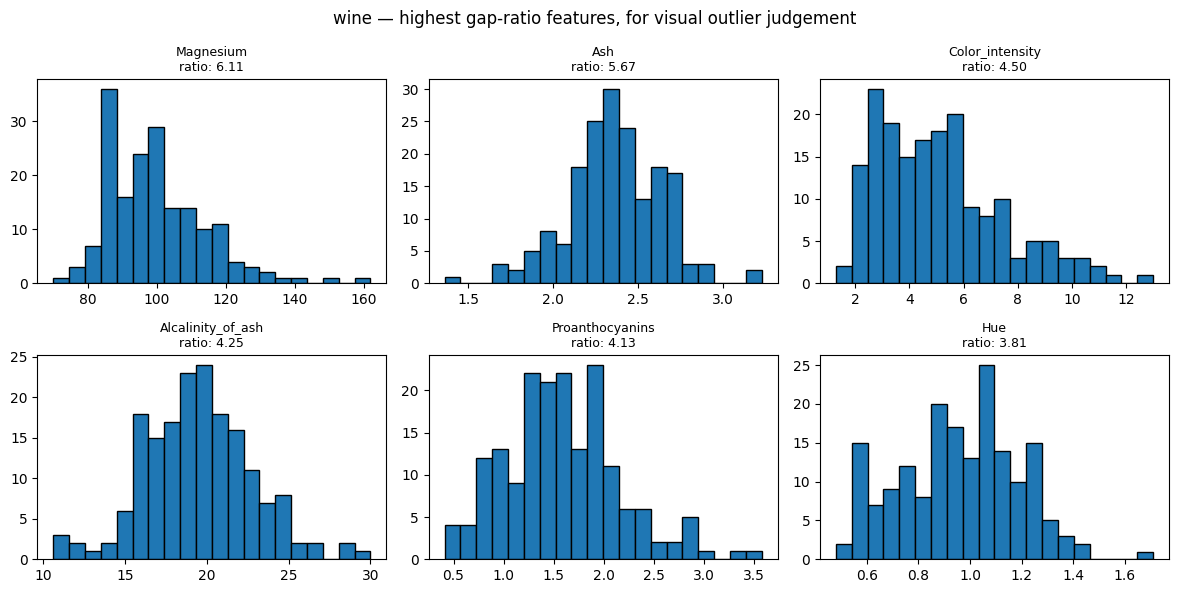

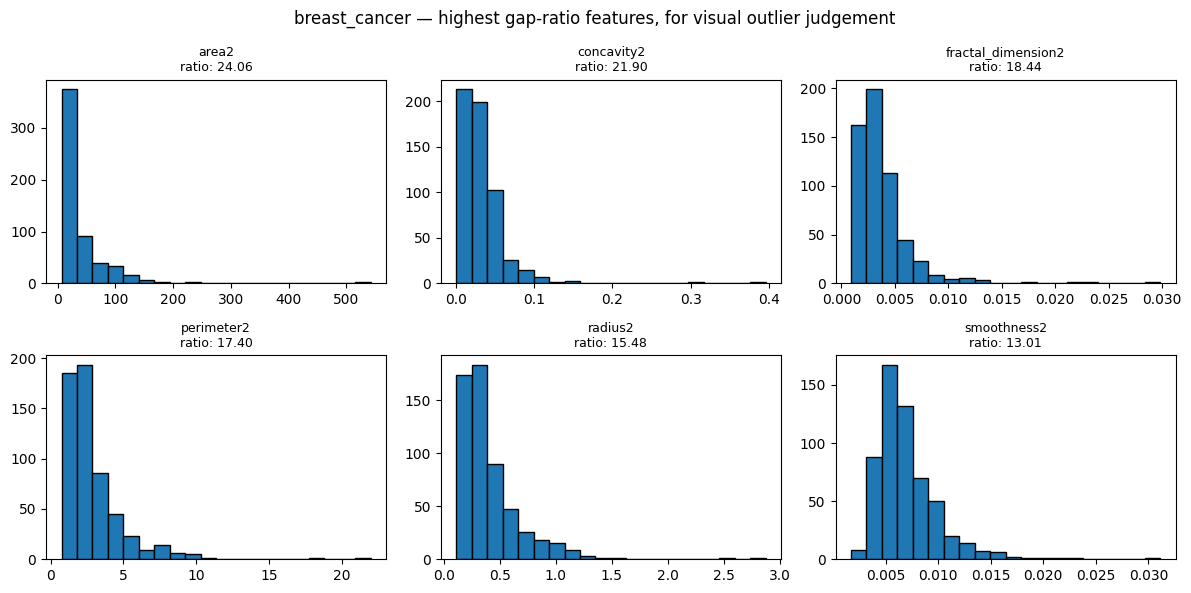

In [20]:
plot_top_ratio_histograms("wine", datasets["wine"].data.features, dq_outliers["wine"])
plot_top_ratio_histograms("breast_cancer", datasets["breast_cancer"].data.features, dq_outliers["breast_cancer"])

## Auto MPG: missing horsepower values

Auto MPG has 6 missing values (1.5%) in `horsepower`, out of 398
instances. Before deciding how to handle these, the missingness pattern
was checked by comparing the mean of every other feature between rows
with missing horsepower and rows with horsepower present.

The comparison shows a consistent, systematic difference rather than a
random pattern: rows with missing horsepower have lower mean displacement
(129.00 vs 194.41), fewer cylinders (4.33 vs 5.47), lower weight (2502.67
vs 2977.58), higher acceleration (17.32 vs 15.54), and a slightly more
recent model year (78.00 vs 75.98) than rows with horsepower present.
These missing values are therefore not missing at random; they
concentrate in smaller, lighter, more recent vehicles.

This has two consequences for handling the missing values:

- Dropping the 6 rows would systematically remove smaller, lighter
  vehicles from the dataset rather than a random subset, biasing the
  remaining data toward larger cars.
- Mean or median imputation would assign these smaller cars a
  horsepower value typical of the dataset as a whole, which does not
  match the pattern shown by their other features.

Horsepower was therefore imputed using linear regression on displacement
and weight, the two features most strongly correlated with horsepower in
the earlier correlation check (0.897 and 0.865 respectively), so the
imputed values are consistent with the pattern already present in each
row's other features rather than an unconditional dataset average.

In [21]:
def impute_horsepower(X):
    X = X.copy()
    known = X[X["horsepower"].notnull()]
    unknown = X[X["horsepower"].isnull()]

    predictors = ["displacement", "weight"]
    model = LinearRegression()
    model.fit(known[predictors], known["horsepower"])

    predicted = model.predict(unknown[predictors])
    X.loc[X["horsepower"].isnull(), "horsepower"] = predicted
    return X, dict(zip(unknown.index, predicted.round(1)))

datasets["auto_mpg"].data.features, imputed_values = impute_horsepower(datasets["auto_mpg"].data.features)
print("Imputed horsepower values:", imputed_values)
print("Remaining missing values:", datasets["auto_mpg"].data.features["horsepower"].isnull().sum())

Imputed horsepower values: {32: np.float64(70.7), 126: np.float64(104.9), 330: np.float64(65.3), 336: np.float64(89.8), 354: np.float64(73.9), 374: np.float64(93.8)}
Remaining missing values: 0


# Preprocessing

## Preprocessing: Wine

Wine requires minimal preprocessing. No missing values, no nominal
features requiring encoding, and no severe feature redundancy (the
strongest correlation, Total_phenols/Flavanoids at 0.865, is moderate
rather than severe).

Two items were addressed:

- **Feature scaling**: features vary by orders of magnitude (Proline
  ranges 278–1680, Ash ranges 1.36–3.23), confirmed in the Data Quality
  Report. All features were standardised (zero mean, unit variance)
  before training, since gradient-based optimisation is sensitive to
  feature scale.
- **Magnesium outlier**: one isolated high value was visually confirmed
  earlier. This was retained rather than removed, since Wine is a small
  dataset (178 instances) and a single point is unlikely to meaningfully
  distort training; standardisation reduces its relative influence
  without discarding real data.

In [22]:
def preprocess_wine(ds):
    X = ds.data.features.copy()
    y = ds.data.targets.copy()

    scaler = StandardScaler()
    X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=X.columns, index=X.index)

    return X_scaled, y, scaler

wine_X_processed, wine_y, wine_scaler = preprocess_wine(datasets["wine"])
print(wine_X_processed.describe().round(3))

       Alcohol  Malicacid      Ash  Alcalinity_of_ash  Magnesium  \
count  178.000    178.000  178.000            178.000    178.000   
mean    -0.000     -0.000   -0.000             -0.000     -0.000   
std      1.003      1.003    1.003              1.003      1.003   
min     -2.434     -1.433   -3.679             -2.671     -2.088   
25%     -0.788     -0.659   -0.572             -0.689     -0.824   
50%      0.061     -0.423   -0.024              0.002     -0.122   
75%      0.836      0.670    0.698              0.602      0.510   
max      2.260      3.109    3.156              3.155      4.371   

       Total_phenols  Flavanoids  Nonflavanoid_phenols  Proanthocyanins  \
count        178.000     178.000               178.000          178.000   
mean           0.000      -0.000                 0.000           -0.000   
std            1.003       1.003                 1.003            1.003   
min           -2.107      -1.696                -1.868           -2.069   
25%         

## Preprocessing: Ionosphere

Ionosphere required one structural fix before scaling. Attribute2 was
confirmed constant across all 351 instances (cardinality 1, standard
deviation 0.000 in the Data Quality Report), carrying zero information
for any model, and was dropped. Attribute1 is near-constant (2 unique
values, 89.2% at value 1) but was retained, since it is not strictly
zero-information and dropping features was reserved for genuinely
constant ones.

No missing values and no nominal features requiring encoding were found;
all remaining features are continuous radar signal measurements ranging
approximately -1 to 1. Unlike Wine, features here already share a
similar raw scale, but standardisation was applied regardless for
consistency with the other five datasets and for training stability.

In [23]:
def preprocess_ionosphere(ds):
    X = ds.data.features.copy()
    y = ds.data.targets.copy()

    constant_cols = X.columns[X.nunique() == 1].tolist()
    print("Dropping constant columns:", constant_cols)
    X = X.drop(columns=constant_cols)

    scaler = StandardScaler()
    X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=X.columns, index=X.index)

    return X_scaled, y, scaler

ionosphere_X_processed, ionosphere_y, ionosphere_scaler = preprocess_ionosphere(datasets["ionosphere"])
print(ionosphere_X_processed.shape)
print(ionosphere_X_processed.describe().round(3))

Dropping constant columns: ['Attribute2']
(351, 33)
       Attribute1  Attribute3  Attribute4  Attribute5  Attribute6  Attribute7  \
count     351.000     351.000     351.000     351.000     351.000     351.000   
mean        0.000      -0.000      -0.000      -0.000      -0.000      -0.000   
std         1.001       1.001       1.001       1.001       1.001       1.001   
min        -2.870      -3.303      -2.369      -3.084      -2.425      -3.151   
25%         0.348      -0.340      -0.248      -0.363      -0.306      -0.689   
50%         0.348       0.462      -0.064       0.401      -0.202       0.363   
75%         0.348       0.722       0.340       0.768       0.475       0.852   
max         0.348       0.722       2.168       0.768       1.921       0.915   

       Attribute8  Attribute9  Attribute10  Attribute11  Attribute12  \
count     351.000     351.000      351.000      351.000      351.000   
mean       -0.000      -0.000       -0.000        0.000        0.000   
st

## Preprocessing: Breast Cancer Wisconsin (Diagnostic)

No missing values and no nominal features requiring encoding were found;
all 30 features are continuous cell-measurement values.

Two data quality observations were made and deliberately not acted on:

- **Multicollinearity**: 28 feature pairs show correlation above 0.85,
  several near 1.0 (radius1/perimeter1 at 0.998), concentrated in the
  radius/perimeter/area groups, which are geometrically related
  measurements of the same underlying shape rather than independent
  variables. These were retained rather than removed. Unlike linear
  regression, a neural network is not broken by correlated inputs, and
  the resulting ill-conditioning of the error surface is directly
  relevant to the comparison this assignment is testing: SCG and
  LeapFrog are specifically designed to handle curvature and elongated
  error surfaces better than plain SGD, so retaining this redundancy
  preserves a genuine source of landscape complexity rather than
  removing it.
- **Outliers**: a small number of isolated high values were visually
  confirmed in several standard-error ("2"-suffix) features against an
  underlying exponential distribution shape. These were retained, since
  the dataset is of moderate size (569 instances) and standardisation
  reduces their relative influence without discarding real data.

Features were standardised (zero mean, unit variance) before training,
consistent with Wine and Ionosphere, given the confirmed wide scale
disparity between features (e.g. area1 ranges 143.5–2501.0, smoothness1
ranges 0.053–0.163).

In [24]:
def preprocess_breast_cancer(ds):
    X = ds.data.features.copy()
    y = ds.data.targets.copy()

    scaler = StandardScaler()
    X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=X.columns, index=X.index)

    return X_scaled, y, scaler

breast_cancer_X_processed, breast_cancer_y, breast_cancer_scaler = preprocess_breast_cancer(datasets["breast_cancer"])
print(breast_cancer_X_processed.shape)
print(breast_cancer_X_processed.describe().round(3))

(569, 30)
       radius1  texture1  perimeter1    area1  smoothness1  compactness1  \
count  569.000   569.000     569.000  569.000      569.000       569.000   
mean    -0.000     0.000      -0.000   -0.000       -0.000         0.000   
std      1.001     1.001       1.001    1.001        1.001         1.001   
min     -2.030    -2.229      -1.985   -1.454       -3.112        -1.610   
25%     -0.689    -0.726      -0.692   -0.667       -0.711        -0.747   
50%     -0.215    -0.105      -0.236   -0.295       -0.035        -0.222   
75%      0.469     0.584       0.500    0.364        0.636         0.494   
max      3.971     4.652       3.976    5.251        4.771         4.568   

       concavity1  concave_points1  symmetry1  fractal_dimension1  radius2  \
count     569.000          569.000    569.000             569.000  569.000   
mean        0.000           -0.000      0.000               0.000    0.000   
std         1.001            1.001      1.001               1.001    1.

## Preprocessing: Yacht Hydrodynamics

No missing values, no severe feature redundancy (correlation check
returned no pairs above 0.85), and no nominal features requiring
encoding — all six features are continuous measurements drawn from a
discrete factorial experimental design (22 hull forms at 14 Froude
numbers each, 22 x 14 = 308 instances).

The gap-comparison outlier check flagged several features with high
ratios, most notably Length.displacement.ratio at 43.00. Visual
inspection showed these are false positives caused by the method itself:
with only 4-17 unique values per feature, the quartiles land adjacent to
distinct experimental settings rather than describing a continuous
distribution, producing large gap ratios with no corresponding extreme
value. All six histograms show a small number of separated spikes
(Multimodal, per course vocabulary), not a central cluster with isolated
extremes. No values were treated as outliers.

Features were standardised (zero mean, unit variance) before training,
for consistency with the other five datasets.

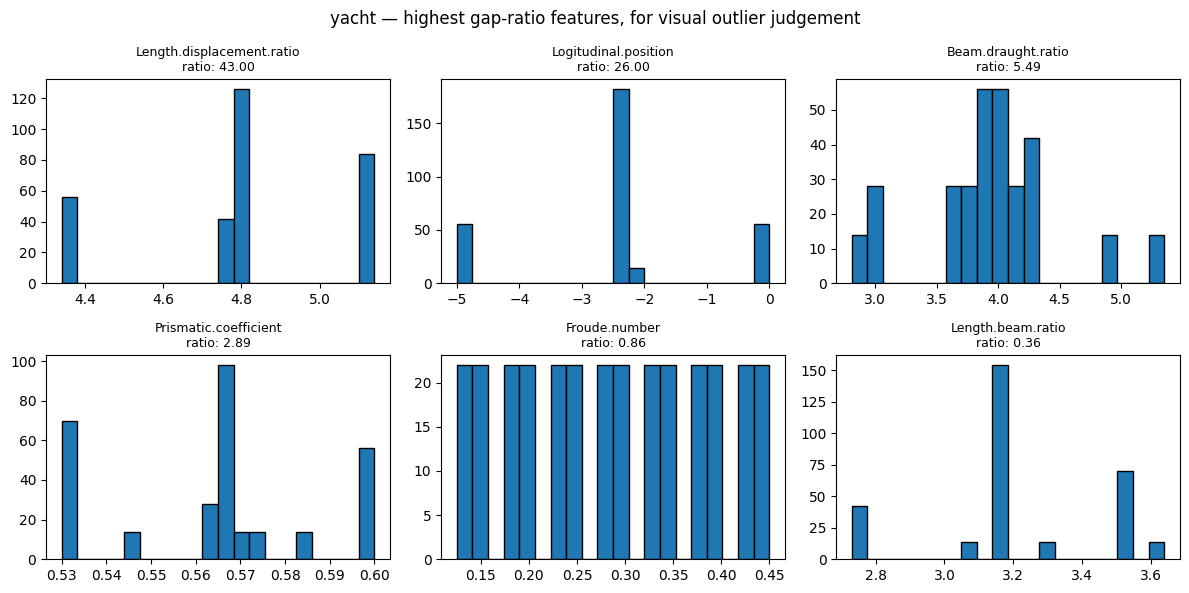

In [25]:
plot_top_ratio_histograms("yacht", datasets["yacht"].data.features, dq_outliers["yacht"])

In [26]:
def preprocess_yacht(ds):
    X = ds.data.features.copy()
    y = ds.data.targets.copy()

    scaler = StandardScaler()
    X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=X.columns, index=X.index)

    return X_scaled, y, scaler

yacht_X_processed, yacht_y, yacht_scaler = preprocess_yacht(datasets["yacht"])
print(yacht_X_processed.shape)
print(yacht_X_processed.describe().round(3))

(308, 6)
       Logitudinal.position  Prismatic.coefficient  Length.displacement.ratio  \
count               308.000                308.000                    308.000   
mean                  0.000                 -0.000                      0.000   
std                   1.002                  1.002                      1.002   
min                  -1.733                 -1.468                     -1.776   
25%                  -0.012                 -0.780                     -0.074   
50%                   0.054                  0.037                     -0.034   
75%                   0.054                  0.424                      1.232   
max                   1.577                  1.542                      1.391   

       Beam.draught.ratio  Length.beam.ratio  Froude.number  
count             308.000            308.000        308.000  
mean                0.000              0.000         -0.000  
std                 1.002              1.002          1.002  
min          

## Preprocessing: Auto MPG

Missing values in horsepower were already resolved via regression
imputation (see earlier section), using displacement and weight as
predictors.

`origin` was confirmed nominal (country-of-origin code, no natural
order) and one-hot encoded. `cylinders` and `model_year` were confirmed
genuinely ordinal/discrete-continuous rather than nominal, and were kept
as numeric features.

The gap-comparison check flagged acceleration and horsepower as the
highest-ratio features. Visual inspection showed both as ordinary
right-skewed distributions with a gradual tail, not a distinct separated
cluster of extreme values; no outliers were confirmed or removed.

Feature redundancy (displacement/cylinders at 0.951, displacement/weight
at 0.933, cylinders/weight at 0.896, horsepower/weight at 0.865) was
retained rather than acted on, consistent with the decision made for
Breast Cancer Wisconsin: neural networks are not broken by correlated
inputs, and this reflects genuine, physically meaningful relationships
between engine size, weight, and cylinder count rather than a data
defect.

Numeric features were standardised (zero mean, unit variance); the
one-hot encoded origin columns were left unscaled, since scaling binary
indicator columns is unnecessary and standard practice.

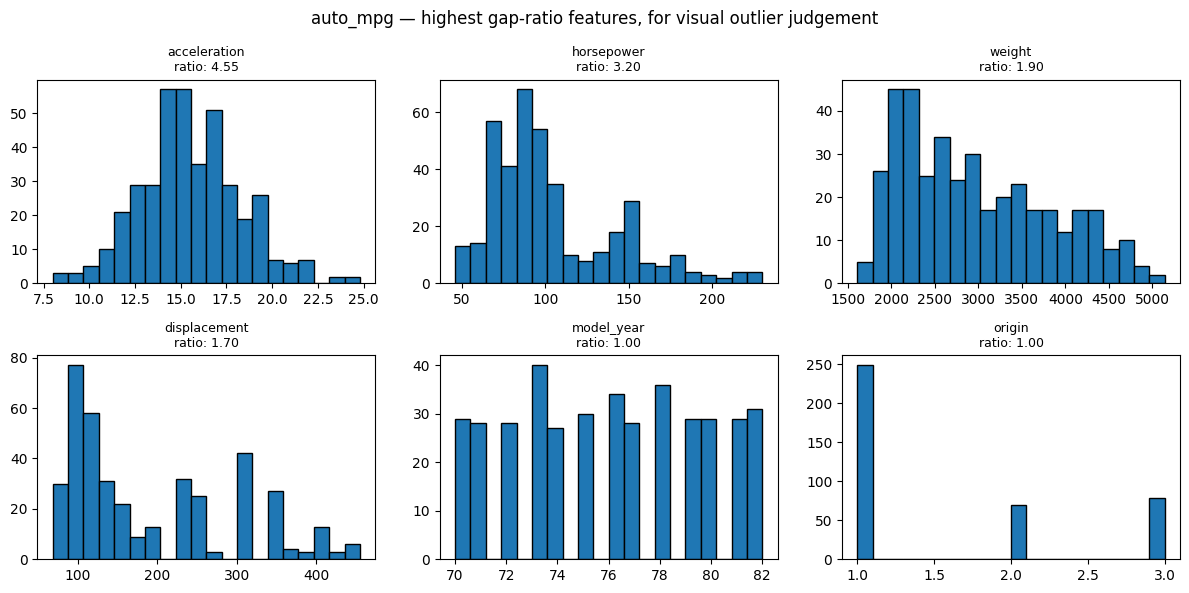

In [27]:
plot_top_ratio_histograms("auto_mpg", datasets["auto_mpg"].data.features, dq_outliers["auto_mpg"])

In [28]:
def preprocess_auto_mpg(ds):
    X = ds.data.features.copy()
    y = ds.data.targets.copy()

    X = pd.get_dummies(X, columns=["origin"], prefix="origin")

    numeric_cols = ["displacement", "cylinders", "horsepower", "weight", "acceleration", "model_year"]
    scaler = StandardScaler()
    X_scaled = X.copy()
    X_scaled[numeric_cols] = scaler.fit_transform(X[numeric_cols])

    origin_cols = [c for c in X.columns if c.startswith("origin_")]
    X_scaled[origin_cols] = X_scaled[origin_cols].astype(int)

    return X_scaled, y, scaler

auto_mpg_X_processed, auto_mpg_y, auto_mpg_scaler = preprocess_auto_mpg(datasets["auto_mpg"])
print(auto_mpg_X_processed.shape)
print(auto_mpg_X_processed.head())

(398, 9)
   displacement  cylinders  horsepower    weight  acceleration  model_year  \
0      1.090604   1.498191    0.675383  0.630870     -1.295498   -1.627426   
1      1.503514   1.498191    1.589718  0.854333     -1.477038   -1.627426   
2      1.196232   1.498191    1.197860  0.550470     -1.658577   -1.627426   
3      1.061796   1.498191    1.197860  0.546923     -1.295498   -1.627426   
4      1.042591   1.498191    0.936621  0.565841     -1.840117   -1.627426   

   origin_1  origin_2  origin_3  
0         1         0         0  
1         1         0         0  
2         1         0         0  
3         1         0         0  
4         1         0         0  


## Preprocessing: Energy Efficiency

No missing values. The regression target was already narrowed to Y2
(cooling load), selected over Y1 based on a larger observed nonlinearity
gap.

X6 (orientation) was confirmed nominal (compass orientation code, no
natural order) and one-hot encoded. X1, X2, X3, X4, X5, X7, and X8 were
confirmed genuinely continuous, drawn from a small number of discrete
building-shape settings (12 base shapes), and were kept numeric.

The gap-comparison check returned low ratios for this dataset relative
to the other five (maximum 3.00 for X3). Visual inspection confirmed all
flagged features show a small number of distinct, separated spikes
(Multimodal, per course vocabulary) reflecting the discrete experimental
design, not a central cluster with isolated extremes. No outliers were
confirmed.

Feature redundancy (X1/X2 at 0.992, X4/X5 at 0.973, and several weaker
pairs) was retained rather than acted on, consistent with the decision
made for Breast Cancer Wisconsin and Auto MPG.

Numeric features were standardised (zero mean, unit variance); the
one-hot encoded orientation columns were left unscaled.

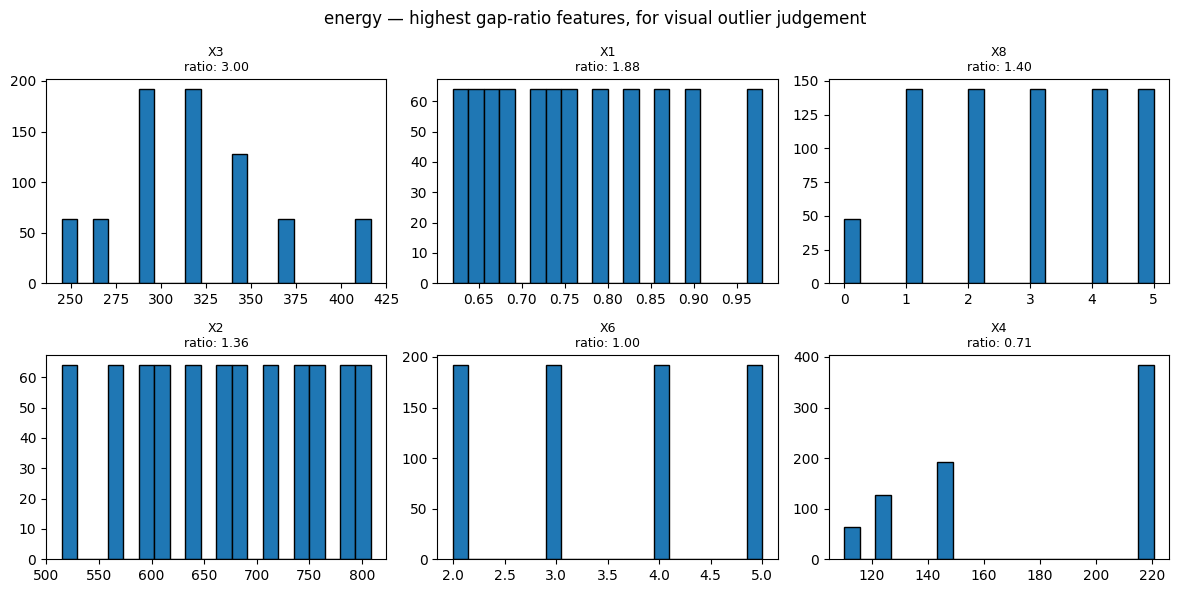

In [29]:
plot_top_ratio_histograms("energy", datasets["energy"].data.features, dq_outliers["energy"])

In [30]:
def preprocess_energy(ds):
    X = ds.data.features.copy()
    y = ds.data.targets.copy()

    X = pd.get_dummies(X, columns=["X6"], prefix="X6")

    numeric_cols = ["X1", "X2", "X3", "X4", "X5", "X7", "X8"]
    scaler = StandardScaler()
    X_scaled = X.copy()
    X_scaled[numeric_cols] = scaler.fit_transform(X[numeric_cols])

    orientation_cols = [c for c in X.columns if c.startswith("X6_")]
    X_scaled[orientation_cols] = X_scaled[orientation_cols].astype(int)

    return X_scaled, y, scaler

energy_X_processed, energy_y, energy_scaler = preprocess_energy(datasets["energy"])
print(energy_X_processed.shape)
print(energy_X_processed.head())

(768, 11)
         X1        X2        X3        X4   X5        X7        X8  X6_2  \
0  2.041777 -1.785875 -0.561951 -1.470077  1.0 -1.760447 -1.814575     1   
1  2.041777 -1.785875 -0.561951 -1.470077  1.0 -1.760447 -1.814575     0   
2  2.041777 -1.785875 -0.561951 -1.470077  1.0 -1.760447 -1.814575     0   
3  2.041777 -1.785875 -0.561951 -1.470077  1.0 -1.760447 -1.814575     0   
4  1.284979 -1.229239  0.000000 -1.198678  1.0 -1.760447 -1.814575     1   

   X6_3  X6_4  X6_5  
0     0     0     0  
1     1     0     0  
2     0     1     0  
3     0     0     1  
4     0     0     0  


# Algorithms

### Shared network core

A single hidden-layer feedforward neural network, following the notation
and structure from Topic 5 (slide 133): inputs z, hidden layer y, output
layer o, weights v (input-to-hidden) and w (hidden-to-output), each layer
with a bias unit. Weights are initialised as v, w ~ U[-1/sqrt(fan-in),
1/sqrt(fan-in)], per slide 151.

The loss function is sum-squared error (SSE), matching the SGD pseudocode
given on slide 144-145. The hidden layer uses sigmoid activation; the
output layer uses sigmoid for classification tasks (targets 0/1) or
linear activation for regression tasks (continuous targets), since SSE
with a sigmoid output would otherwise constrain regression targets to the
(0, 1) range.

This is built once and shared across all three training algorithms
(SGD, SCG, LeapFrog): each optimiser only needs the current weight
vector, the error, and the gradient, all provided by this class, so the
comparison between algorithms is controlled and fair — only the update
rule differs.

Weights are represented internally as two matrices (v and w,

In [31]:
X_wine_tr, X_wine_val, T_wine_tr, T_wine_val = train_test_split(
    wine_X_processed.values,
    pd.get_dummies(wine_y.iloc[:, 0]).values.astype(float),
    test_size=0.15, random_state=0, stratify=wine_y.iloc[:, 0]
)

In [32]:
class FeedforwardNN:
    def __init__(self, n_inputs, n_hidden, n_outputs, output_activation="sigmoid", seed=None):
        self.n_inputs = n_inputs
        self.n_hidden = n_hidden
        self.n_outputs = n_outputs
        self.output_activation = output_activation

        rng = np.random.default_rng(seed)

        v_bound = 1.0 / np.sqrt(n_inputs + 1)
        w_bound = 1.0 / np.sqrt(n_hidden + 1)

        self.v = rng.uniform(-v_bound, v_bound, size=(n_hidden, n_inputs + 1))
        self.w = rng.uniform(-w_bound, w_bound, size=(n_outputs, n_hidden + 1))

        self.complexity_units = 0

    def reset_complexity_units(self):
        self.complexity_units = 0

    @staticmethod
    def _sigmoid(net):
        net_clipped = np.clip(net, -500, 500)
        return 1.0 / (1.0 + np.exp(-net_clipped))

    def _output_act(self, net):
        if self.output_activation == "sigmoid":
            return self._sigmoid(net)
        elif self.output_activation == "linear":
            return net
        else:
            raise ValueError(f"Unknown output_activation: {self.output_activation}")

    def _output_deriv(self, o):
        if self.output_activation == "sigmoid":
            return o * (1.0 - o)
        elif self.output_activation == "linear":
            return np.ones_like(o)

    def forward(self, X):
        n_patterns = X.shape[0]
        Z = np.hstack([X, -np.ones((n_patterns, 1))])
        net_y = Z @ self.v.T
        Y = self._sigmoid(net_y)
        Y_bias = np.hstack([Y, -np.ones((n_patterns, 1))])
        net_o = Y_bias @ self.w.T
        O = self._output_act(net_o)
        return Z, Y, Y_bias, O

    def predict(self, X):
        _, _, _, O = self.forward(X)
        return O

    def compute_error(self, X, T, count=True):
        _, _, _, O = self.forward(X)
        if count:
            self.complexity_units += 1
        return 0.5 * np.sum((T - O) ** 2)

    def get_weights(self):
        return np.concatenate([self.v.ravel(), self.w.ravel()])

    def set_weights(self, flat):
        v_size = self.v.size
        self.v = flat[:v_size].reshape(self.v.shape)
        self.w = flat[v_size:].reshape(self.w.shape)

    def compute_gradient(self, X, T, count=True, clip_norm=50.0):
      Z, Y, Y_bias, O = self.forward(X)

      delta_o = (T - O) * self._output_deriv(O)
      grad_w = -(delta_o.T @ Y_bias)

      delta_y = (delta_o @ self.w[:, :-1]) * (Y * (1.0 - Y))
      grad_v = -(delta_y.T @ Z)

      grad = np.concatenate([grad_v.ravel(), grad_w.ravel()])

      if count:
          self.complexity_units += 3

      grad_norm = np.linalg.norm(grad)
      if clip_norm is not None and grad_norm > clip_norm:
          grad = grad * (clip_norm / grad_norm)

      return grad

    def n_weights(self):
        return self.v.size + self.w.size

In [33]:
np.random.seed(0)
X_test = wine_X_processed.values
T_test = pd.get_dummies(wine_y.iloc[:, 0]).values.astype(float)

nn = FeedforwardNN(n_inputs=X_test.shape[1], n_hidden=5, n_outputs=T_test.shape[1],
                    output_activation="sigmoid", seed=42)

print("Initial error:", nn.compute_error(X_test, T_test))
print("Number of weights:", nn.n_weights())
grad = nn.compute_gradient(X_test, T_test)
print("Gradient shape:", grad.shape, "matches weight count:", grad.shape[0] == nn.n_weights())

Initial error: 65.7543010103515
Number of weights: 88
Gradient shape: (88,) matches weight count: True


## SGD (stochastic gradient descent)

Following the pseudocode from slide 144: for each epoch, the training
set is shuffled (slide 154, to prevent the network learning the order of
pattern presentation), then weights are updated after each
pattern/mini-batch (feedforward, compute error, backpropagate,
accumulate total error). Momentum is included, per slide 154, as a
fraction of the previous weight change added to the current one, to
smooth the search trajectory.

Stopping conditions follow slide 150: training halts when a maximum
number of epochs is reached, or when the average weight change becomes
very small.

This function uses the network's existing `get_weights`,
`set_weights`, and `compute_gradient` interface, so it plugs into the
same `FeedforwardNN` object SCG and LeapFrog will also use — only the
update rule differs.

In [34]:
def train_sgd(nn, X_train, T_train, X_val=None, T_val=None,
              eta=0.1, alpha=0.9, batch_size=1, max_epochs=200, tol=1e-6, seed=0, verbose=True):
    rng = np.random.default_rng(seed)
    n_patterns = X_train.shape[0]

    weights = nn.get_weights()
    velocity = np.zeros_like(weights)

    train_error_history = []
    val_error_history = []
    complexity_history = []

    for epoch in range(max_epochs):
        idx = rng.permutation(n_patterns)
        X_shuf, T_shuf = X_train[idx], T_train[idx]

        for start in range(0, n_patterns, batch_size):
            X_batch = X_shuf[start:start + batch_size]
            T_batch = T_shuf[start:start + batch_size]

            grad = nn.compute_gradient(X_batch, T_batch)
            velocity = alpha * velocity - eta * grad
            weights = weights + velocity
            nn.set_weights(weights)

        train_error = nn.compute_error(X_train, T_train)
        train_error_history.append(train_error)
        complexity_history.append(nn.complexity_units)

        if X_val is not None:
            val_error_history.append(nn.compute_error(X_val, T_val))

        if verbose and epoch % 20 == 0:
            msg = f"Epoch {epoch}: train error = {train_error:.4f}"
            if X_val is not None:
                msg += f", val error = {val_error_history[-1]:.4f}"
            print(msg)

        if epoch > 0 and abs(train_error_history[-2] - train_error_history[-1]) < tol:
            if verbose:
                print(f"Stopped early at epoch {epoch}: weight change below tolerance")
            break

    return weights, train_error_history, val_error_history, complexity_history

In [35]:
nn_sgd_check = FeedforwardNN(n_inputs=X_wine_tr.shape[1], n_hidden=5, n_outputs=T_wine_tr.shape[1],
                              output_activation="sigmoid", seed=42)

print("Initial error:", nn_sgd_check.compute_error(X_wine_tr, T_wine_tr, count=False))

final_weights_sgd, train_hist_sgd, val_hist_sgd, cu_hist_sgd = train_sgd(
    nn_sgd_check, X_wine_tr, T_wine_tr, X_wine_val, T_wine_val,
    eta=0.1, alpha=0.9, batch_size=1, max_epochs=200
)

print("Final train error:", train_hist_sgd[-1])
print("Final val error:", val_hist_sgd[-1])
print("Complexity units used:", cu_hist_sgd[-1])
print("Epochs actually run:", len(train_hist_sgd))

Initial error: 55.82886743064446
Epoch 0: train error = 11.4521, val error = 1.6767
Epoch 20: train error = 0.1383, val error = 0.0424
Epoch 40: train error = 0.0637, val error = 0.0392
Epoch 60: train error = 0.0404, val error = 0.0392
Epoch 80: train error = 0.0294, val error = 0.0396
Epoch 100: train error = 0.0231, val error = 0.0403
Epoch 120: train error = 0.0189, val error = 0.0408
Epoch 140: train error = 0.0160, val error = 0.0409
Epoch 160: train error = 0.0138, val error = 0.0413
Epoch 180: train error = 0.0121, val error = 0.0419
Final train error: 0.01089541435635806
Final val error: 0.04196569156631385
Complexity units used: 90999
Epochs actually run: 200


## SCG (scaled conjugate gradient)

Following the 7-step algorithm from Møller (1993), Section 5, which your
Topic 5 slides mirror closely in notation. Unlike SGD, SCG has no
critical user-tuned parameters (learning rate, momentum): the step size
is derived automatically each iteration via a Levenberg-Marquardt-style
scaling parameter (lambda), which is raised when the local quadratic
approximation is unreliable and lowered when it is working well, and no
line search is performed.

The algorithm requires the network's error and gradient at arbitrary
weight vectors (not just the current one), so this function temporarily
sets the network's weights to evaluate a trial point, then restores them
- this is what `E(w)` and `E_grad(w)` do below, using the same
`get_weights`/`set_weights`/`compute_gradient` interface SGD used.

In [36]:
def train_scg(nn, X_train, T_train, X_val=None, T_val=None,
              sigma=1e-4, lambda_init=1e-6, max_iterations=500, tol=1e-6, verbose=True):
    N = nn.n_weights()

    def E(w_vec):
        nn.set_weights(w_vec)
        return nn.compute_error(X_train, T_train)

    def E_grad(w_vec):
        nn.set_weights(w_vec)
        return nn.compute_gradient(X_train, T_train)

    w = nn.get_weights().copy()
    r = -E_grad(w)
    p = r.copy()
    success = True
    lam = lambda_init
    lam_bar = 0.0
    k = 1
    raw_delta = None
    p_norm2 = np.dot(p, p)

    train_error_history = [E(w)]
    val_error_history = [nn.compute_error(X_val, T_val, count=False)] if X_val is not None else []
    complexity_history = [nn.complexity_units]

    for iteration in range(max_iterations):
        if success:
            p_norm2 = np.dot(p, p)
            sigma_k = sigma / np.sqrt(p_norm2)
            s = (E_grad(w + sigma_k * p) - E_grad(w)) / sigma_k
            raw_delta = np.dot(p, s)

        delta = raw_delta + (lam - lam_bar) * p_norm2

        if delta <= 0:
            lam_bar = 2 * (lam - delta / p_norm2)
            delta = -delta + lam * p_norm2
            lam = lam_bar

        mu = np.dot(p, r)
        alpha = mu / delta

        current_E = E(w)
        trial_E = E(w + alpha * p)
        Delta = 2 * delta * (current_E - trial_E) / (mu ** 2)

        if Delta >= 0:
            w = w + alpha * p
            r_new = -E_grad(w)
            lam_bar = 0.0
            success = True

            if k % N == 0:
                p = r_new.copy()
            else:
                beta = (np.dot(r_new, r_new) - np.dot(r_new, r)) / mu
                p = r_new + beta * p
            r = r_new

            if Delta >= 0.75:
                lam = 0.25 * lam
        else:
            lam_bar = lam
            success = False

        if Delta < 0.25:
            lam = lam + delta * (1 - Delta) / p_norm2

        current_error = E(w)
        train_error_history.append(current_error)
        complexity_history.append(nn.complexity_units)

        if X_val is not None:
            val_error_history.append(nn.compute_error(X_val, T_val, count=False))

        if verbose and iteration % 20 == 0:
            msg = f"Iteration {iteration}: train error = {current_error:.4f}"
            if X_val is not None:
                msg += f", val error = {val_error_history[-1]:.4f}"
            print(msg)

        if np.sqrt(np.dot(r, r)) < tol:
            if verbose:
                print(f"Converged at iteration {iteration}: gradient norm below tolerance")
            break

        k += 1

    nn.set_weights(w)
    return w, train_error_history, val_error_history, complexity_history

In [37]:
nn_scg_check = FeedforwardNN(n_inputs=X_wine_tr.shape[1], n_hidden=5, n_outputs=T_wine_tr.shape[1],
                              output_activation="sigmoid", seed=42)

print("Initial error:", nn_scg_check.compute_error(X_wine_tr, T_wine_tr, count=False))

final_weights_scg, train_hist_scg, val_hist_scg, cu_hist_scg = train_scg(
    nn_scg_check, X_wine_tr, T_wine_tr, X_wine_val, T_wine_val, max_iterations=500
)

print("Final train error:", train_hist_scg[-1])
print("Final val error:", val_hist_scg[-1])
print("Complexity units used:", cu_hist_scg[-1])
print("Iterations actually run:", len(train_hist_scg))

Initial error: 55.82886743064446
Iteration 0: train error = 46.8672, val error = 8.2813
Iteration 20: train error = 0.0819, val error = 0.0136
Iteration 40: train error = 0.0001, val error = 0.0178
Converged at iteration 58: gradient norm below tolerance
Final train error: 6.909554604974375e-07
Final val error: 0.1516784853898175
Complexity units used: 712
Iterations actually run: 60


## LeapFrog (LFOP1(b))

Following the improved algorithm from Snyman (1983), which adds an
automatic time step selection routine to the original 1982 dynamic
method. The network's weights are treated as the position of a particle
with unit mass, moving under the gradient of the error function acting
as a force. Kinetic energy is monitored at each step, and the velocity
is reset (with a restart) whenever it decreases, which is what forces
the particle toward a minimum rather than oscillating forever, per the
original paper's energy-conservation argument.

Time step (Delta t) is automatically magnified after consecutive
successful steps and halved when the angle between successive gradient
directions suggests it has become too large (a_{k+1}.a_k <= 0 for m
consecutive steps), following LFOP1(b)'s specific procedure rather than
the simpler fixed-schedule approach in the original 1982 paper.

In [38]:
def train_leapfrog(nn, X_train, T_train, X_val=None, T_val=None,
                    dt_init=0.5, delta=1.0, m=3, delta1=0.001, eps=1e-5,
                    max_steps=2000, verbose=True):
    def E(w_vec):
        nn.set_weights(w_vec)
        return nn.compute_error(X_train, T_train)

    def grad(w_vec):
        nn.set_weights(w_vec)
        return nn.compute_gradient(X_train, T_train)

    x = nn.get_weights().copy()
    dt = dt_init
    a = -grad(x)
    v = 0.5 * a * dt

    x_prev = x.copy()
    v_prev = v.copy()
    s = 0

    train_error_history = [E(x)]
    val_error_history = [nn.compute_error(X_val, T_val, count=False)] if X_val is not None else []
    complexity_history = [nn.complexity_units]

    for k in range(max_steps):
        dx = v * dt
        step_norm = np.linalg.norm(dx)
        if step_norm >= delta:
            v_step = delta * v / (np.linalg.norm(v) * dt) if np.linalg.norm(v) > 0 else v
            dx = v_step * dt

        x_next = x + dx
        a_next = -grad(x_next)
        v_next = v + a_next * dt

        if np.dot(a_next, a) > 0:
            s = 0
        else:
            s += 1

        if s >= m:
            dt = dt / 2
            x_next = (x + x_prev) / 2
            v_next = (v + v_prev) / 4
            s = 0

        if np.linalg.norm(v_next) > np.linalg.norm(v):
            dt = dt * (1 + delta1)

        x_prev, v_prev = x, v
        x, v, a = x_next, v_next, a_next

        current_error = E(x)
        train_error_history.append(current_error)
        complexity_history.append(nn.complexity_units)

        if X_val is not None:
            val_error_history.append(nn.compute_error(X_val, T_val, count=False))

        if verbose and k % 100 == 0:
            msg = f"Step {k}: train error = {current_error:.4f}, dt = {dt:.5f}"
            if X_val is not None:
                msg += f", val error = {val_error_history[-1]:.4f}"
            print(msg)

        if np.linalg.norm(a) <= eps:
            if verbose:
                print(f"Converged at step {k}: gradient norm below tolerance")
            break

    nn.set_weights(x)
    return x, train_error_history, val_error_history, complexity_history

In [39]:
nn_lf_check = FeedforwardNN(n_inputs=X_wine_tr.shape[1], n_hidden=5, n_outputs=T_wine_tr.shape[1],
                             output_activation="sigmoid", seed=42)

print("Initial error:", nn_lf_check.compute_error(X_wine_tr, T_wine_tr, count=False))

final_weights_lf, train_hist_lf, val_hist_lf, cu_hist_lf = train_leapfrog(
    nn_lf_check, X_wine_tr, T_wine_tr, X_wine_val, T_wine_val, max_steps=2000
)

print("Final train error:", train_hist_lf[-1])
print("Final val error:", val_hist_lf[-1])
print("Complexity units used:", cu_hist_lf[-1])
print("Steps actually run:", len(train_hist_lf))

Initial error: 55.82886743064446
Step 0: train error = 46.8889, dt = 0.50050, val error = 8.2864
Step 100: train error = 0.0000, dt = 0.54108, val error = 0.0000
Converged at step 102: gradient norm below tolerance
Final train error: 4.395272556485416e-07
Final val error: 2.378375006824899e-17
Complexity units used: 416
Steps actually run: 104


## Stage B: per-dataset train/validation splits

A fixed 70/15/15 split is created for each dataset: 70% training, 15%
validation (used throughout hidden-unit and hyperparameter tuning), and
15% held out completely untouched until the final comparison stage. The
same split is reused across all three algorithms per dataset, so that
differences in results are attributable to the algorithm rather than to
which data each one happened to see.

**Classification target encoding.** Wine (3 classes) is one-hot encoded
into 3 output units, since a single binary output cannot represent more
than two categories. Ionosphere and Breast Cancer Wisconsin (2 classes
each) use a single output unit with the target mapped to 0/1, following
the logistic regression convention taught on slide 60-61: "before we
train a logistic regression model we map the binary target feature
levels to 0 or 1", with error computed between the 0/1 target and the
single sigmoid prediction. This also avoids the redundancy of two
one-hot units whose targets are always complementary for a binary
problem.

**Stratification** is used for all three classification splits, to
preserve class proportions between training and validation — this
matters most for Breast Cancer Wisconsin, given its confirmed 37/63
class imbalance.

**Regression datasets** (Yacht, Auto MPG, Energy) use a plain,
non-stratified split, since there is no class balance concern for a
continuous target.

In [40]:
from sklearn.model_selection import train_test_split

splits = {}

# --- Wine: 3 classes, one-hot ---
T_wine_full = pd.get_dummies(wine_y.iloc[:, 0]).values.astype(float)
X_tr, X_temp, T_tr, T_temp = train_test_split(
    wine_X_processed.values, T_wine_full, test_size=0.30, random_state=0,
    stratify=wine_y.iloc[:, 0]
)
X_val, X_test, T_val, T_test = train_test_split(
    X_temp, T_temp, test_size=0.5, random_state=0, stratify=T_temp.argmax(axis=1)
)
splits["wine"] = dict(X_tr=X_tr, X_val=X_val, X_test=X_test, T_tr=T_tr, T_val=T_val, T_test=T_test)

# --- Ionosphere: 2 classes, single binary output ---
ionosphere_target_map = {"g": 1.0, "b": 0.0}
T_ionosphere_full = ionosphere_y.iloc[:, 0].map(ionosphere_target_map).values.reshape(-1, 1)
X_tr, X_temp, T_tr, T_temp = train_test_split(
    ionosphere_X_processed.values, T_ionosphere_full, test_size=0.30, random_state=0,
    stratify=T_ionosphere_full.ravel()
)
X_val, X_test, T_val, T_test = train_test_split(
    X_temp, T_temp, test_size=0.5, random_state=0, stratify=T_temp.ravel()
)
splits["ionosphere"] = dict(X_tr=X_tr, X_val=X_val, X_test=X_test, T_tr=T_tr, T_val=T_val, T_test=T_test)

# --- Breast Cancer Wisconsin: 2 classes, single binary output ---
breast_cancer_target_map = {"M": 1.0, "B": 0.0}
T_bc_full = breast_cancer_y.iloc[:, 0].map(breast_cancer_target_map).values.reshape(-1, 1)
X_tr, X_temp, T_tr, T_temp = train_test_split(
    breast_cancer_X_processed.values, T_bc_full, test_size=0.30, random_state=0,
    stratify=T_bc_full.ravel()
)
X_val, X_test, T_val, T_test = train_test_split(
    X_temp, T_temp, test_size=0.5, random_state=0, stratify=T_temp.ravel()
)
splits["breast_cancer"] = dict(X_tr=X_tr, X_val=X_val, X_test=X_test, T_tr=T_tr, T_val=T_val, T_test=T_test)

# --- Regression datasets: plain split, single continuous output ---
for key, X_processed, y_processed in [
    ("yacht", yacht_X_processed, yacht_y),
    ("auto_mpg", auto_mpg_X_processed, auto_mpg_y),
    ("energy", energy_X_processed, energy_y),
]:
    T_full = y_processed.values.astype(float).reshape(-1, 1) if y_processed.values.ndim == 1 else y_processed.values.astype(float)
    X_tr, X_temp, T_tr, T_temp = train_test_split(X_processed.values, T_full, test_size=0.30, random_state=0)
    X_val, X_test, T_val, T_test = train_test_split(X_temp, T_temp, test_size=0.5, random_state=0)
    splits[key] = dict(X_tr=X_tr, X_val=X_val, X_test=X_test, T_tr=T_tr, T_val=T_val, T_test=T_test)

for key, s in splits.items():
    print(f"{key}: train={s['X_tr'].shape}, val={s['X_val'].shape}, test={s['X_test'].shape}, "
          f"T shape={s['T_tr'].shape}")

wine: train=(124, 13), val=(27, 13), test=(27, 13), T shape=(124, 3)
ionosphere: train=(245, 33), val=(53, 33), test=(53, 33), T shape=(245, 1)
breast_cancer: train=(398, 30), val=(85, 30), test=(86, 30), T shape=(398, 1)
yacht: train=(215, 6), val=(46, 6), test=(47, 6), T shape=(215, 1)
auto_mpg: train=(278, 9), val=(60, 9), test=(60, 9), T shape=(278, 1)
energy: train=(537, 11), val=(115, 11), test=(116, 11), T shape=(537, 1)


In [41]:
yacht_target_scaler = StandardScaler()
yacht_y_scaled = pd.DataFrame(yacht_target_scaler.fit_transform(yacht_y.values.reshape(-1, 1)),
                               columns=yacht_y.columns, index=yacht_y.index)

auto_mpg_target_scaler = StandardScaler()
auto_mpg_y_scaled = pd.DataFrame(auto_mpg_target_scaler.fit_transform(auto_mpg_y.values.reshape(-1, 1)),
                                  columns=auto_mpg_y.columns, index=auto_mpg_y.index)

energy_target_scaler = StandardScaler()
energy_y_scaled = pd.DataFrame(energy_target_scaler.fit_transform(energy_y.values.reshape(-1, 1)),
                                columns=energy_y.columns, index=energy_y.index)

for key, X_processed, y_scaled in [
    ("yacht", yacht_X_processed, yacht_y_scaled),
    ("auto_mpg", auto_mpg_X_processed, auto_mpg_y_scaled),
    ("energy", energy_X_processed, energy_y_scaled),
]:
    T_full = y_scaled.values.astype(float)
    X_tr, X_temp, T_tr, T_temp = train_test_split(X_processed.values, T_full, test_size=0.30, random_state=0)
    X_val, X_test, T_val, T_test = train_test_split(X_temp, T_temp, test_size=0.5, random_state=0)
    splits[key] = dict(X_tr=X_tr, X_val=X_val, X_test=X_test, T_tr=T_tr, T_val=T_val, T_test=T_test)

print("Regression targets re-scaled and splits rebuilt.")

Regression targets re-scaled and splits rebuilt.


## Stage C: hidden-unit search

For each dataset, candidate hidden-unit counts are evaluated by running
all three algorithms (not just one) with a modest, fixed training budget,
and averaging their validation error per candidate. The hidden-unit count
with the best average validation error is selected and shared by all
three algorithms for that dataset going forward.

This avoids letting any single algorithm's characteristics dictate the
architecture, while still keeping architecture fixed across algorithms
per dataset, per the reasoning discussed (Moller, 1993, Section 6.2; the
general confounding-control principle from Lindauer and Hutter, 2019).

A fixed, modest budget (100 epochs for SGD, 100 iterations for SCG, 300
steps for LeapFrog) is used for the search itself, since full convergence
is not needed to compare

In [42]:
task_type = {
    "wine": "classification", "ionosphere": "classification", "breast_cancer": "classification",
    "yacht": "regression", "auto_mpg": "regression", "energy": "regression",
}

def quick_run(algo, X_tr, T_tr, X_val, T_val, n_hidden, output_activation, seed=42, budget=None):
    nn = FeedforwardNN(n_inputs=X_tr.shape[1], n_hidden=n_hidden, n_outputs=T_tr.shape[1],
                        output_activation=output_activation, seed=seed)
    if algo == "sgd":
        _, _, val_hist, _ = train_sgd(nn, X_tr, T_tr, X_val, T_val,
                                       max_epochs=budget or 100, verbose=False)
    elif algo == "scg":
        _, _, val_hist, _ = train_scg(nn, X_tr, T_tr, X_val, T_val,
                                       max_iterations=budget or 100, verbose=False)
    elif algo == "leapfrog":
        _, _, val_hist, _ = train_leapfrog(nn, X_tr, T_tr, X_val, T_val,
                                            max_steps=budget or 300, verbose=False)
    else:
        raise ValueError(f"Unknown algo: {algo}")
    return val_hist[-1] if val_hist else np.nan

In [43]:
hidden_unit_candidates = [2, 5, 10, 15, 20]
algorithms = ["sgd", "scg", "leapfrog"]
search_budget = {"sgd": 300, "scg": 200, "leapfrog": 500}

hidden_units_selected = {}
hidden_unit_search_results = {}

for key, s in splits.items():
    output_activation = "sigmoid" if task_type[key] == "classification" else "linear"
    candidate_scores = {}

    for h in hidden_unit_candidates:
        scores = []
        for algo in algorithms:
            val_err = quick_run(algo, s["X_tr"], s["T_tr"], s["X_val"], s["T_val"],
                                 n_hidden=h, output_activation=output_activation,
                                 budget=search_budget[algo])
            scores.append(val_err)
        finite_scores = [sc for sc in scores if np.isfinite(sc)]
        candidate_scores[h] = np.mean(finite_scores) if finite_scores else np.inf

    best_h = min(candidate_scores, key=candidate_scores.get)
    hidden_units_selected[key] = best_h
    hidden_unit_search_results[key] = candidate_scores

    print(f"{key}: {candidate_scores} -> selected {best_h}")

wine: {2: np.float64(0.0013799748690910552), 5: np.float64(0.16705700081129995), 10: np.float64(0.3342589867337573), 15: np.float64(0.5001065820307401), 20: np.float64(0.4897659459402772)} -> selected 2
ionosphere: {2: np.float64(3.6971346094898916), 5: np.float64(2.370360149439027), 10: np.float64(2.160233950563563), 15: np.float64(2.7571571820123366), 20: np.float64(2.5186040514269394)} -> selected 10
breast_cancer: {2: np.float64(2.0260135983475007), 5: np.float64(2.507713092749236), 10: np.float64(2.775228511588702), 15: np.float64(2.630879265388084), 20: np.float64(5.375673189506319)} -> selected 2
yacht: {2: np.float64(1.4620040011176154), 5: np.float64(1.9736068196705316), 10: np.float64(3.4910995353797745), 15: np.float64(14.180934869216955), 20: np.float64(4.535554363778675)} -> selected 2
auto_mpg: {2: np.float64(50.9513674538984), 5: np.float64(61.95368709316873), 10: np.float64(31.392032210947168), 15: np.float64(10.454972373814583), 20: np.float64(40.565759252809805)} -> s

In [44]:
print("Hidden units selected per dataset:")
for key, h in hidden_units_selected.items():
    print(f"  {key}: {h}")

Hidden units selected per dataset:
  wine: 2
  ionosphere: 10
  breast_cancer: 2
  yacht: 2
  auto_mpg: 15
  energy: 5


## Stage D: hyperparameter tuning

With hidden-unit counts fixed per dataset from Stage C, each algorithm's
own control parameters are tuned separately, per dataset, via grid
search on the validation split. Each combination is evaluated once
(not repeated), given compute constraints; the combination with the
lowest validation error is selected and logged with its score.

- SGD: learning rate (eta) and momentum (alpha).
- SCG: sigma and initial lambda.
- LeapFrog: initial time step (dt_init) and maximum stepsize (delta).

SCG and LeapFrog use smaller grids than SGD, consistent with Moller
(1993) and Snyman's own papers both framing these algorithms as
comparatively insensitive to their control parameters.

In [45]:
sgd_grid = [{"eta": eta, "alpha": alpha} for eta in [0.01, 0.05, 0.1, 0.3] for alpha in [0.0, 0.5, 0.9]]
scg_grid = [{"sigma": sigma, "lambda_init": lam} for sigma in [1e-3, 1e-4, 1e-5] for lam in [1e-6, 1e-4]]
leapfrog_grid = [{"dt_init": dt, "delta": d} for dt in [0.1, 0.5, 1.0] for d in [0.5, 1.0, 3.0]]

param_grids = {"sgd": sgd_grid, "scg": scg_grid, "leapfrog": leapfrog_grid}
tuning_budget = {"sgd": 300, "scg": 200, "leapfrog": 500}

best_params = {}
tuning_results = {}

for key, s in splits.items():
    output_activation = "sigmoid" if task_type[key] == "classification" else "linear"
    n_hidden = hidden_units_selected[key]
    best_params[key] = {}
    tuning_results[key] = {}

    for algo in algorithms:
        results = []
        for params in param_grids[algo]:
            nn = FeedforwardNN(n_inputs=s["X_tr"].shape[1], n_hidden=n_hidden,
                                n_outputs=s["T_tr"].shape[1], output_activation=output_activation, seed=42)
            if algo == "sgd":
                _, _, val_hist, _ = train_sgd(nn, s["X_tr"], s["T_tr"], s["X_val"], s["T_val"],
                                               max_epochs=tuning_budget[algo], verbose=False, **params)
            elif algo == "scg":
                _, _, val_hist, _ = train_scg(nn, s["X_tr"], s["T_tr"], s["X_val"], s["T_val"],
                                               max_iterations=tuning_budget[algo], verbose=False, **params)
            elif algo == "leapfrog":
                _, _, val_hist, _ = train_leapfrog(nn, s["X_tr"], s["T_tr"], s["X_val"], s["T_val"],
                                                     max_steps=tuning_budget[algo], verbose=False, **params)
            val_err = val_hist[-1] if val_hist and np.isfinite(val_hist[-1]) else np.inf
            results.append((params, val_err))

        results.sort(key=lambda r: r[1])
        best_params[key][algo] = results[0][0]
        tuning_results[key][algo] = results

        print(f"{key} / {algo}: best = {results[0][0]}, val_error = {results[0][1]:.4f}")

wine / sgd: best = {'eta': 0.3, 'alpha': 0.9}, val_error = 0.0020
wine / scg: best = {'sigma': 1e-05, 'lambda_init': 0.0001}, val_error = 0.0000
wine / leapfrog: best = {'dt_init': 0.5, 'delta': 0.5}, val_error = 0.0000
ionosphere / sgd: best = {'eta': 0.3, 'alpha': 0.9}, val_error = 0.9912
ionosphere / scg: best = {'sigma': 0.0001, 'lambda_init': 1e-06}, val_error = 1.5136
ionosphere / leapfrog: best = {'dt_init': 0.5, 'delta': 1.0}, val_error = 3.1119
breast_cancer / sgd: best = {'eta': 0.01, 'alpha': 0.0}, val_error = 1.1717
breast_cancer / scg: best = {'sigma': 1e-05, 'lambda_init': 0.0001}, val_error = 1.4884
breast_cancer / leapfrog: best = {'dt_init': 1.0, 'delta': 3.0}, val_error = 0.9991
yacht / sgd: best = {'eta': 0.01, 'alpha': 0.9}, val_error = 0.0601
yacht / scg: best = {'sigma': 0.001, 'lambda_init': 0.0001}, val_error = 0.0494
yacht / leapfrog: best = {'dt_init': 0.1, 'delta': 0.5}, val_error = 2.1979
auto_mpg / sgd: best = {'eta': 0.1, 'alpha': 0.5}, val_error = 2.8834


In [46]:
leapfrog_grid_regression = [{"dt_init": dt, "delta": d} for dt in [0.01, 0.05, 0.1] for d in [0.5, 1.0, 3.0]]

for key in ["yacht", "auto_mpg", "energy"]:
    s = splits[key]
    n_hidden = hidden_units_selected[key]
    results = []
    for params in leapfrog_grid_regression:
        nn = FeedforwardNN(n_inputs=s["X_tr"].shape[1], n_hidden=n_hidden,
                            n_outputs=s["T_tr"].shape[1], output_activation="linear", seed=42)
        _, _, val_hist, _ = train_leapfrog(nn, s["X_tr"], s["T_tr"], s["X_val"], s["T_val"],
                                             max_steps=tuning_budget["leapfrog"], verbose=False, **params)
        val_err = val_hist[-1] if val_hist and np.isfinite(val_hist[-1]) else np.inf
        results.append((params, val_err))

    results.sort(key=lambda r: r[1])
    if results[0][1] < tuning_results[key]["leapfrog"][0][1]:
        best_params[key]["leapfrog"] = results[0][0]
        tuning_results[key]["leapfrog"] = results
        print(f"{key} / leapfrog IMPROVED: best = {results[0][0]}, val_error = {results[0][1]:.4f}")
    else:
        print(f"{key} / leapfrog: no improvement over original grid ({tuning_results[key]['leapfrog'][0][1]:.4f})")

yacht / leapfrog: no improvement over original grid (2.1979)
auto_mpg / leapfrog: no improvement over original grid (5.1244)
energy / leapfrog: no improvement over original grid (12.7512)


## Training budget sufficiency check

The fixed training budgets used throughout this study (300 epochs for
stochastic gradient descent, 200 iterations for scaled conjugate
gradient, 500 steps for LeapFrog) were set for computational
feasibility, given the scale of the hidden-unit search, hyperparameter
grids, and cross-validation already conducted. To confirm these budgets
were sufficient, each algorithm was re-run on one classification
dataset (Ionosphere) and one function approximation dataset (Auto MPG),
using double the original budget, and the resulting validation error
was compared against the original budget's result.

In [47]:
budget_check_results = []

test_datasets = ["ionosphere", "auto_mpg"]
extended_budget = {"sgd": 600, "scg": 400, "leapfrog": 1000}

for key in test_datasets:
    s = splits[key]
    n_hidden = hidden_units_selected[key]
    output_activation = "sigmoid" if task_type[key] == "classification" else "linear"

    for algo in algorithms:
        params = best_params[key][algo]

        nn_orig = FeedforwardNN(n_inputs=s["X_tr"].shape[1], n_hidden=n_hidden,
                                 n_outputs=s["T_tr"].shape[1], output_activation=output_activation, seed=42)
        nn_ext = FeedforwardNN(n_inputs=s["X_tr"].shape[1], n_hidden=n_hidden,
                                n_outputs=s["T_tr"].shape[1], output_activation=output_activation, seed=42)

        if algo == "sgd":
            _, _, val_hist_orig, _ = train_sgd(nn_orig, s["X_tr"], s["T_tr"], s["X_val"], s["T_val"],
                                                max_epochs=tuning_budget[algo], verbose=False, **params)
            _, _, val_hist_ext, _ = train_sgd(nn_ext, s["X_tr"], s["T_tr"], s["X_val"], s["T_val"],
                                               max_epochs=extended_budget[algo], verbose=False, **params)
        elif algo == "scg":
            _, _, val_hist_orig, _ = train_scg(nn_orig, s["X_tr"], s["T_tr"], s["X_val"], s["T_val"],
                                                max_iterations=tuning_budget[algo], verbose=False, **params)
            _, _, val_hist_ext, _ = train_scg(nn_ext, s["X_tr"], s["T_tr"], s["X_val"], s["T_val"],
                                               max_iterations=extended_budget[algo], verbose=False, **params)
        elif algo == "leapfrog":
            _, _, val_hist_orig, _ = train_leapfrog(nn_orig, s["X_tr"], s["T_tr"], s["X_val"], s["T_val"],
                                                      max_steps=tuning_budget[algo], verbose=False, **params)
            _, _, val_hist_ext, _ = train_leapfrog(nn_ext, s["X_tr"], s["T_tr"], s["X_val"], s["T_val"],
                                                     max_steps=extended_budget[algo], verbose=False, **params)

        orig_err = val_hist_orig[-1] if val_hist_orig else np.nan
        ext_err = val_hist_ext[-1] if val_hist_ext else np.nan
        pct_change = 100 * (orig_err - ext_err) / orig_err if orig_err else np.nan

        budget_check_results.append(dict(
            dataset=key, algo=algo,
            original_budget=tuning_budget[algo], original_val_error=round(orig_err, 5),
            extended_budget=extended_budget[algo], extended_val_error=round(ext_err, 5),
            pct_change=round(pct_change, 2)
        ))

budget_check_df = pd.DataFrame(budget_check_results)
print(budget_check_df.to_string(index=False))

   dataset     algo  original_budget  original_val_error  extended_budget  extended_val_error  pct_change
ionosphere      sgd              300             0.99123              600             1.09507      -10.48
ionosphere      scg              200             1.51359              400             1.51359        0.00
ionosphere leapfrog              500             3.11193             1000             3.11193        0.00
  auto_mpg      sgd              300             2.88344              600             3.31355      -14.92
  auto_mpg      scg              200             2.75569              400             3.39534      -23.21
  auto_mpg leapfrog              500             5.12440             1000             6.82560      -33.20


## Stage E: final comparison (repeated k-fold cross-validation)

With hidden-unit counts (Stage C) and hyperparameters (Stage D) locked
in, each algorithm is now evaluated using repeated k-fold cross-validation
on the full dataset (5 folds, repeated 3 times, 15 runs per algorithm
per dataset), rather than the single train/validation split used for
tuning. This is what produces multiple paired samples per dataset for
the statistical comparison in Stage F.

The same folds are reused across all three algorithms per dataset
(SGD, SCG, and LeapFrog see identical training/test data on a given
fold), but the network's random weight initialisation seed varies
across every fold, so the spread of results also reflects sensitivity
to initial conditions (Kolen and Pollack, 1990), not only the fold's
particular data split.

Recorded per fold: the task performance metric (accuracy and macro-F1
for classification; RMSE, in original units via the stored target
scaler, and R^2 for regression), complexity units consumed (Moller,
1993), and whether the algorithm converged within its training budget.

In [48]:
full_data = {}

# Classification
full_data["wine"] = dict(
    X=wine_X_processed.values,
    T=pd.get_dummies(wine_y.iloc[:, 0]).values.astype(float),
    y_strat=wine_y.iloc[:, 0].values
)
full_data["ionosphere"] = dict(
    X=ionosphere_X_processed.values,
    T=ionosphere_y.iloc[:, 0].map({"g": 1.0, "b": 0.0}).values.reshape(-1, 1),
    y_strat=ionosphere_y.iloc[:, 0].values
)
full_data["breast_cancer"] = dict(
    X=breast_cancer_X_processed.values,
    T=breast_cancer_y.iloc[:, 0].map({"M": 1.0, "B": 0.0}).values.reshape(-1, 1),
    y_strat=breast_cancer_y.iloc[:, 0].values
)

# Regression (using the target-scaled versions from the Stage C fix)
full_data["yacht"] = dict(X=yacht_X_processed.values, T=yacht_y_scaled.values.astype(float), scaler=yacht_target_scaler)
full_data["auto_mpg"] = dict(X=auto_mpg_X_processed.values, T=auto_mpg_y_scaled.values.astype(float), scaler=auto_mpg_target_scaler)
full_data["energy"] = dict(X=energy_X_processed.values, T=energy_y_scaled.values.astype(float), scaler=energy_target_scaler)

for key, d in full_data.items():
    print(f"{key}: X={d['X'].shape}, T={d['T'].shape}")

wine: X=(178, 13), T=(178, 3)
ionosphere: X=(351, 33), T=(351, 1)
breast_cancer: X=(569, 30), T=(569, 1)
yacht: X=(308, 6), T=(308, 1)
auto_mpg: X=(398, 9), T=(398, 1)
energy: X=(768, 11), T=(768, 1)


In [49]:
cv_budget = {"sgd": 300, "scg": 200, "leapfrog": 500}
algo_seed_offset = {"sgd": 0, "scg": 1, "leapfrog": 2}
n_splits, n_repeats = 5, 3

def train_one_fold(algo, X_tr, T_tr, X_te, T_te, n_hidden, output_activation, params, seed):
    nn = FeedforwardNN(n_inputs=X_tr.shape[1], n_hidden=n_hidden, n_outputs=T_tr.shape[1],
                        output_activation=output_activation, seed=seed)
    if algo == "sgd":
        _, train_hist, _, cu_hist = train_sgd(nn, X_tr, T_tr, max_epochs=cv_budget[algo],
                                               verbose=False, **params)
    elif algo == "scg":
        _, train_hist, _, cu_hist = train_scg(nn, X_tr, T_tr, max_iterations=cv_budget[algo],
                                               verbose=False, **params)
    elif algo == "leapfrog":
        _, train_hist, _, cu_hist = train_leapfrog(nn, X_tr, T_tr, max_steps=cv_budget[algo],
                                                     verbose=False, **params)
    converged = len(train_hist) < cv_budget[algo]
    return nn, cu_hist[-1] if cu_hist else np.nan, converged

cv_results = []

for key, d in full_data.items():
    X, T = d["X"], d["T"]
    n_hidden = hidden_units_selected[key]
    output_activation = "sigmoid" if task_type[key] == "classification" else "linear"

    if task_type[key] == "classification":
        kf = RepeatedStratifiedKFold(n_splits=n_splits, n_repeats=n_repeats, random_state=0)
        fold_splits = list(kf.split(X, d["y_strat"]))
    else:
        kf = RepeatedKFold(n_splits=n_splits, n_repeats=n_repeats, random_state=0)
        fold_splits = list(kf.split(X))

    for algo in algorithms:
        params = best_params[key][algo]

        for fold_idx, (train_idx, test_idx) in enumerate(fold_splits):
            seed = fold_idx * 100 + algo_seed_offset[algo]
            X_tr, X_te = X[train_idx], X[test_idx]
            T_tr, T_te = T[train_idx], T[test_idx]

            nn, cu, converged = train_one_fold(algo, X_tr, T_tr, X_te, T_te, n_hidden,
                                                output_activation, params, seed)
            preds = nn.predict(X_te)

            if task_type[key] == "classification":
                if T.shape[1] > 1:
                    y_true = T_te.argmax(axis=1)
                    y_pred = preds.argmax(axis=1)
                else:
                    y_true = T_te.ravel()
                    y_pred = (preds.ravel() >= 0.5).astype(int)
                acc = accuracy_score(y_true, y_pred)
                f1 = f1_score(y_true, y_pred, average="macro")
                cv_results.append(dict(dataset=key, algo=algo, fold=fold_idx, accuracy=acc,
                                        macro_f1=f1, complexity_units=cu, converged=converged))
            else:
                y_true_orig = d["scaler"].inverse_transform(T_te)
                y_pred_orig = d["scaler"].inverse_transform(preds)
                rmse = np.sqrt(mean_squared_error(y_true_orig, y_pred_orig))
                r2 = r2_score(y_true_orig, y_pred_orig)
                cv_results.append(dict(dataset=key, algo=algo, fold=fold_idx, rmse=rmse,
                                        r2=r2, complexity_units=cu, converged=converged))

    print(f"{key}: done ({len(fold_splits)} folds x {len(algorithms)} algorithms)")

cv_results_df = pd.DataFrame(cv_results)

wine: done (15 folds x 3 algorithms)
ionosphere: done (15 folds x 3 algorithms)
breast_cancer: done (15 folds x 3 algorithms)
yacht: done (15 folds x 3 algorithms)
auto_mpg: done (15 folds x 3 algorithms)
energy: done (15 folds x 3 algorithms)


In [50]:
summary = cv_results_df.groupby(['dataset', 'algo']).mean(numeric_only=True)
print(summary)

                        fold  accuracy  macro_f1  complexity_units  converged  \
dataset       algo                                                              
auto_mpg      leapfrog   7.0       NaN       NaN       2004.000000   0.000000   
              scg        7.0       NaN       NaN       2355.400000   0.000000   
              sgd        7.0       NaN       NaN     286860.000000   0.000000   
breast_cancer leapfrog   7.0  0.923707  0.889240        449.600000   0.866667   
              scg        7.0  0.969539  0.967431       2234.400000   0.133333   
              sgd        7.0  0.976567  0.974755     409980.000000   0.000000   
energy        leapfrog   7.0       NaN       NaN       2004.000000   0.000000   
              scg        7.0       NaN       NaN       2341.600000   0.000000   
              sgd        7.0       NaN       NaN     553260.000000   0.000000   
ionosphere    leapfrog   7.0  0.867029  0.845088       1196.000000   0.733333   
              scg        7.0

## Final held-out test evaluation

The 15% test partition held out since Stage B was not directly used by
the Stage E cross-validation, which drew its folds from the full
dataset. As a final confirmation that the locked-in architecture and
hyperparameters generalise, one model per algorithm per dataset is
trained on the combined training and validation data and evaluated once
on this untouched test partition, providing a genuinely held-out result
alongside the cross-validation comparison.

In [51]:
test_results = []

for key, s in splits.items():
    n_hidden = hidden_units_selected[key]
    output_activation = "sigmoid" if task_type[key] == "classification" else "linear"

    X_trval = np.vstack([s["X_tr"], s["X_val"]])
    T_trval = np.vstack([s["T_tr"], s["T_val"]])

    for algo in algorithms:
        params = best_params[key][algo]
        nn = FeedforwardNN(n_inputs=X_trval.shape[1], n_hidden=n_hidden,
                            n_outputs=T_trval.shape[1], output_activation=output_activation, seed=42)

        if algo == "sgd":
            train_sgd(nn, X_trval, T_trval, max_epochs=cv_budget[algo], verbose=False, **params)
        elif algo == "scg":
            train_scg(nn, X_trval, T_trval, max_iterations=cv_budget[algo], verbose=False, **params)
        elif algo == "leapfrog":
            train_leapfrog(nn, X_trval, T_trval, max_steps=cv_budget[algo], verbose=False, **params)

        preds = nn.predict(s["X_test"])

        if task_type[key] == "classification":
            if s["T_test"].shape[1] > 1:
                y_true = s["T_test"].argmax(axis=1)
                y_pred = preds.argmax(axis=1)
            else:
                y_true = s["T_test"].ravel()
                y_pred = (preds.ravel() >= 0.5).astype(int)
            test_results.append(dict(dataset=key, algo=algo,
                                      accuracy=accuracy_score(y_true, y_pred),
                                      macro_f1=f1_score(y_true, y_pred, average="macro")))
        else:
            scaler = full_data[key]["scaler"]
            y_true_orig = scaler.inverse_transform(s["T_test"])
            y_pred_orig = scaler.inverse_transform(preds)
            test_results.append(dict(dataset=key, algo=algo,
                                      rmse=np.sqrt(mean_squared_error(y_true_orig, y_pred_orig)),
                                      r2=r2_score(y_true_orig, y_pred_orig)))

test_results_df = pd.DataFrame(test_results)
print(test_results_df.to_string(index=False))

      dataset     algo  accuracy  macro_f1      rmse        r2
         wine      sgd  0.962963  0.965899       NaN       NaN
         wine      scg  1.000000  1.000000       NaN       NaN
         wine leapfrog  0.962963  0.965899       NaN       NaN
   ionosphere      sgd  0.886792  0.870098       NaN       NaN
   ionosphere      scg  0.905660  0.896201       NaN       NaN
   ionosphere leapfrog  0.811321  0.767544       NaN       NaN
breast_cancer      sgd  0.965116  0.962429       NaN       NaN
breast_cancer      scg  0.918605  0.912334       NaN       NaN
breast_cancer leapfrog  0.965116  0.962429       NaN       NaN
        yacht      sgd       NaN       NaN  0.759573  0.996522
        yacht      scg       NaN       NaN  7.172004  0.689953
        yacht leapfrog       NaN       NaN  5.700725  0.804113
     auto_mpg      sgd       NaN       NaN  2.830600  0.882445
     auto_mpg      scg       NaN       NaN  3.021115  0.866089
     auto_mpg leapfrog       NaN       NaN  7.018006  0

## Stage F: statistical comparison and consolidation

Two complementary analyses are run on the Stage E cross-validation
results:

- **Paired Wilcoxon signed-rank tests**, per pair of algorithms
  (SGD vs SCG, SGD vs LeapFrog, SCG vs LeapFrog) per dataset, using the
  15 paired fold results as matched samples. This answers, for each
  dataset individually, whether one algorithm's advantage over another
  is statistically significant, following the same approach used in
  Assignment 2.
- **A Dolan and More (2002) performance profile**, summarising all three
  algorithms across all six datasets at once. For each dataset, an
  error metric is defined (1 - accuracy for classification, RMSE for
  regression), and each algorithm's error is expressed as a ratio
  against the best algorithm's error on that dataset. The resulting
  profile shows both which algorithm wins most often (height at
  tau = 1) and how close each algorithm stays to the best even when it
  does not win (how quickly its curve rises).

In [52]:
from scipy.stats import wilcoxon
from itertools import combinations

wilcoxon_results = []

metric_for_task = {"classification": "accuracy", "regression": "rmse"}

for key in full_data.keys():
    metric = metric_for_task[task_type[key]]
    lower_is_better = (metric == "rmse")

    for algo_a, algo_b in combinations(algorithms, 2):
        vals_a = cv_results_df[(cv_results_df.dataset == key) & (cv_results_df.algo == algo_a)][metric].values
        vals_b = cv_results_df[(cv_results_df.dataset == key) & (cv_results_df.algo == algo_b)][metric].values

        if np.all(vals_a == vals_b):
            stat, p = np.nan, 1.0
        else:
            try:
                stat, p = wilcoxon(vals_a, vals_b)
            except ValueError:
                stat, p = np.nan, np.nan

        mean_a, mean_b = np.mean(vals_a), np.mean(vals_b)
        if lower_is_better:
            better = algo_a if mean_a < mean_b else algo_b
        else:
            better = algo_a if mean_a > mean_b else algo_b

        wilcoxon_results.append(dict(
            dataset=key, algo_a=algo_a, algo_b=algo_b, metric=metric,
            mean_a=mean_a, mean_b=mean_b, better=better,
            statistic=stat, p_value=p, significant=(p < 0.05) if p is not None else False
        ))

wilcoxon_df = pd.DataFrame(wilcoxon_results)
print(wilcoxon_df.to_string(index=False))

      dataset algo_a   algo_b   metric   mean_a    mean_b   better  statistic  p_value  significant
         wine    sgd      scg accuracy 0.973810  0.968201      sgd        9.0 0.380455        False
         wine    sgd leapfrog accuracy 0.973810  0.956931      sgd       10.5 0.042273         True
         wine    scg leapfrog accuracy 0.968201  0.956931      scg       11.0 0.323405        False
   ionosphere    sgd      scg accuracy 0.912582  0.861261      sgd        7.5 0.023308         True
   ionosphere    sgd leapfrog accuracy 0.912582  0.867029      sgd        6.0 0.002140         True
   ionosphere    scg leapfrog accuracy 0.861261  0.867029 leapfrog       44.5 0.944234        False
breast_cancer    sgd      scg accuracy 0.976567  0.969539      sgd        8.5 0.028665         True
breast_cancer    sgd leapfrog accuracy 0.976567  0.923707      sgd        4.5 0.010800         True
breast_cancer    scg leapfrog accuracy 0.969539  0.923707      scg       32.5 0.206809        False


### Multiple-comparison correction

18 separate Wilcoxon tests were run (3 algorithm pairs x 6 datasets),
each at alpha = 0.05. Running many independent significance tests
inflates the overall chance of a false positive beyond the nominal 5%
per test. A Holm-Bonferroni correction is applied to adjust for this,
following standard practice for multiple hypothesis testing.

In [53]:
from statsmodels.stats.multitest import multipletests

reject, p_corrected, _, _ = multipletests(wilcoxon_df["p_value"].values, alpha=0.05, method="holm")
wilcoxon_df["p_value_corrected"] = p_corrected
wilcoxon_df["significant_corrected"] = reject

print(wilcoxon_df[["dataset", "algo_a", "algo_b", "p_value", "p_value_corrected",
                    "significant", "significant_corrected"]].to_string(index=False))

      dataset algo_a   algo_b  p_value  p_value_corrected  significant  significant_corrected
         wine    sgd      scg 0.380455           0.970216        False                  False
         wine    sgd leapfrog 0.042273           0.211365         True                  False
         wine    scg leapfrog 0.323405           0.970216        False                  False
   ionosphere    sgd      scg 0.023308           0.172363         True                  False
   ionosphere    sgd leapfrog 0.002140           0.021399         True                   True
   ionosphere    scg leapfrog 0.944234           0.970216        False                  False
breast_cancer    sgd      scg 0.028665           0.172363         True                  False
breast_cancer    sgd leapfrog 0.010800           0.097196         True                  False
breast_cancer    scg leapfrog 0.206809           0.827236        False                  False
        yacht    sgd      scg 0.000610           0.006714   

### LeapFrog regression fold spread

The mean RMSE reported for LeapFrog on the three regression datasets is
sensitive to outlier folds. To check whether the failure is consistent
across folds or driven by a small number of diverging runs, the
distribution of per-fold RMSE is examined directly.

In [54]:
for key in ["yacht", "auto_mpg", "energy"]:
    vals = cv_results_df[(cv_results_df.dataset == key) & (cv_results_df.algo == "leapfrog")]["rmse"]
    print(f"{key}: min={vals.min():.2f}, median={vals.median():.2f}, mean={vals.mean():.2f}, "
          f"max={vals.max():.2f}, std={vals.std():.2f}")

yacht: min=5.32, median=7.46, mean=8.44, max=23.21, std=4.28
auto_mpg: min=3.38, median=18.18, mean=19.22, max=62.65, std=14.06
energy: min=13.59, median=56.48, mean=64.79, max=153.48, std=42.83


Mean error per dataset/algorithm:
algo            leapfrog       scg       sgd
dataset                                     
auto_mpg       19.219400  2.613505  3.096744
breast_cancer   0.076293  0.030461  0.023433
energy         64.790538  1.972411  1.754920
ionosphere      0.132971  0.138739  0.087418
wine            0.043069  0.031799  0.026190
yacht           8.436016  0.952301  1.165963



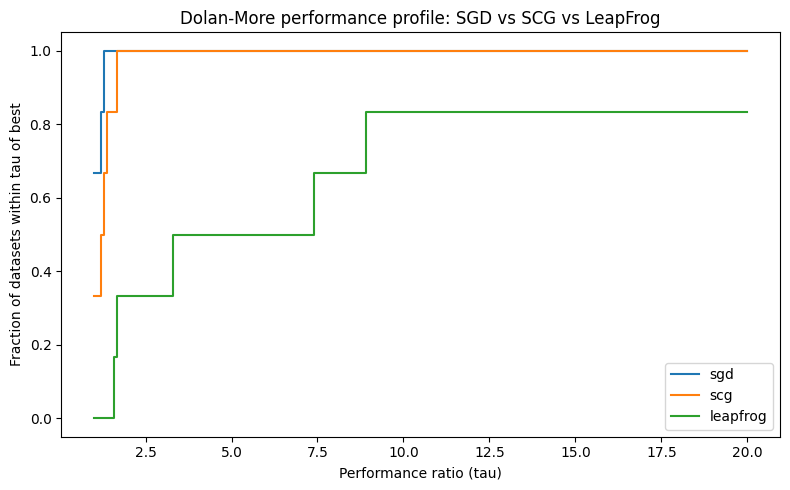

Fraction of datasets where each algorithm was the outright best (tau=1):
algo
leapfrog    0.000000
scg         0.333333
sgd         0.666667
dtype: float64


In [55]:
def error_metric(row):
    if row["dataset"] in ["wine", "ionosphere", "breast_cancer"]:
        return 1 - row["accuracy"]
    else:
        return row["rmse"]

cv_results_df["error"] = cv_results_df.apply(error_metric, axis=1)

mean_error = cv_results_df.groupby(["dataset", "algo"])["error"].mean().unstack()
print("Mean error per dataset/algorithm:")
print(mean_error)
print()

best_per_dataset = mean_error.min(axis=1)
ratio = mean_error.div(best_per_dataset, axis=0)

taus = np.linspace(1, 20, 200)
profile = pd.DataFrame(index=taus, columns=algorithms, dtype=float)

for algo in algorithms:
    for tau in taus:
        profile.loc[tau, algo] = (ratio[algo] <= tau).mean()

plt.figure(figsize=(8, 5))
for algo in algorithms:
    plt.step(taus, profile[algo], where="post", label=algo)
plt.xlabel("Performance ratio (tau)")
plt.ylabel("Fraction of datasets within tau of best")
plt.title("Dolan-More performance profile: SGD vs SCG vs LeapFrog")
plt.legend()
plt.tight_layout()
plt.show()

print("Fraction of datasets where each algorithm was the outright best (tau=1):")
print((ratio == 1.0).mean())